In [31]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


THIS SET OF HYPERPARAMETERS HAVE THE BEST PERFORMANCE SO FAR.

In [32]:
from MIOFlow.utils import generate_steps, set_seeds, config_criterion
from MIOFlow.models import make_model, Autoencoder
from MIOFlow.plots import plot_comparision, plot_losses
from MIOFlow.train import train_ae, training_regimen
from MIOFlow.losses import UOT_loss
from MIOFlow.constants import ROOT_DIR, DATA_DIR, NTBK_DIR, IMGS_DIR, RES_DIR
from MIOFlow.datasets import (
    make_diamonds, make_swiss_roll, make_tree, make_eb_data, 
    make_dyngen_data, make_diamonds_partial_holdout, make_branch_cond, make_dying_example_gaus, make_dying_example_unif
)
from MIOFlow.geo import setup_distance
from MIOFlow.exp import setup_exp
from MIOFlow.eval import generate_plot_data

import os, pandas as pd, numpy as np, \
    seaborn as sns, matplotlib as mpl, matplotlib.pyplot as plt, \
    torch, torch.nn as nn

from tqdm.notebook import tqdm
import time
from sklearn.preprocessing import StandardScaler, MinMaxScaler
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

# Load dataset

In [33]:
phate_dims = 5
df = pd.read_csv('../../data/mioflow_data_w_growth.csv', index_col=0)
df['growth'] = df['growth'].clip(upper=2)
# df['samples'] = df['samples'].max() - df['samples']
assert df.columns[-1] == 'growth'

# Subsample the dataframe so each group has equal number of points
min_group_size = df['samples'].value_counts().min()
df_balanced = df.groupby('samples').apply(lambda x: x.sample(min_group_size, random_state=42)).reset_index(drop=True)

# Verify the balanced dataset
print(df_balanced['samples'].value_counts())

# Replace the original dataframe with the balanced one
df = df_balanced

# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler()
# df[['d1', 'd2']] = scaler.fit_transform(df[['d1', 'd2']])

scaler = MinMaxScaler()
df[['d1', 'd2']] = scaler.fit_transform(df[['d1', 'd2']])

# df[df['samples'] == 0]['growth'] = 0.
# drop the rows whose samples are 3
# df = df[df['samples'] != 3]

samples
0    2832
1    2832
2    2832
3    2832
4    2832
Name: count, dtype: int64


/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


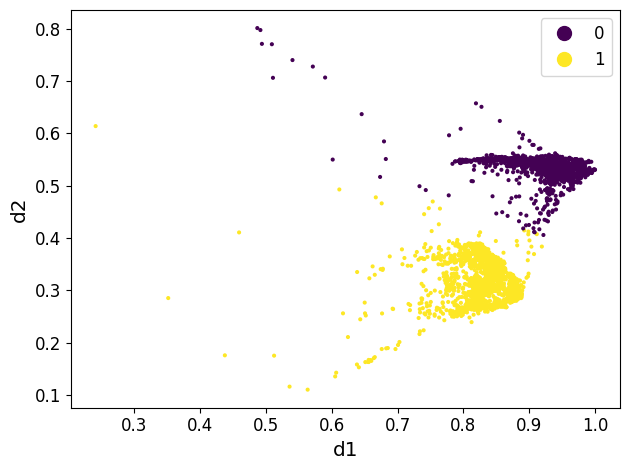

In [34]:
from sklearn.cluster import KMeans

# Cluster the data points from sample 0
kmeans = KMeans(n_clusters=2, random_state=42)
sample0_data = df[df['samples']==0][['d1','d2']]
clusters = kmeans.fit_predict(sample0_data)

import scprep
scprep.plot.scatter2d(sample0_data, c=clusters, cmap='viridis');

In [35]:
# g1 = df.loc[df['samples']==0, 'growth']
# g1[clusters==0] = 0
# df.loc[df['samples']==0, 'growth'] = g1

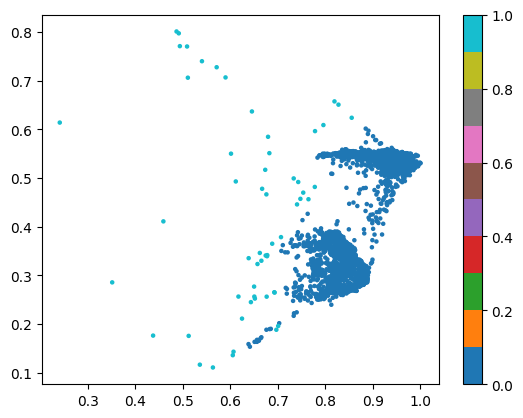

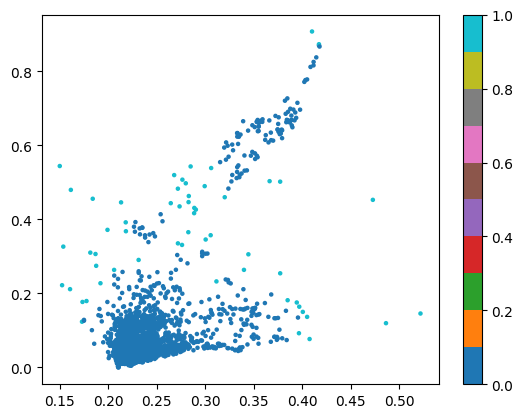

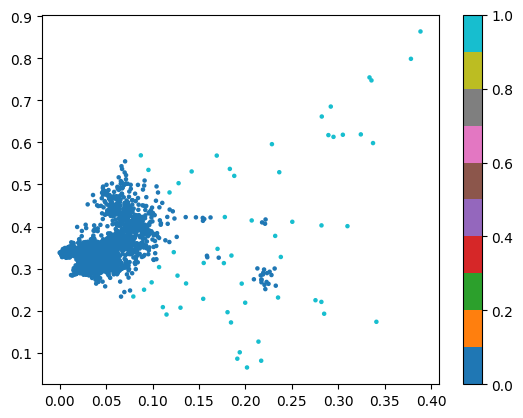

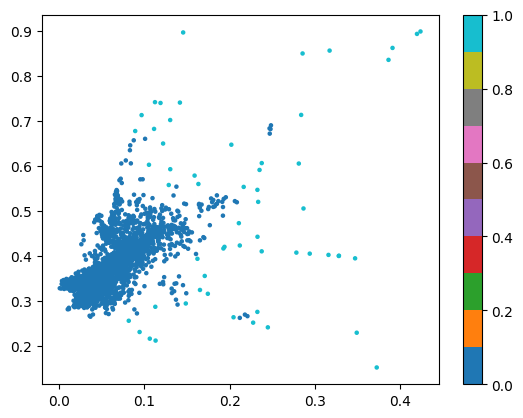

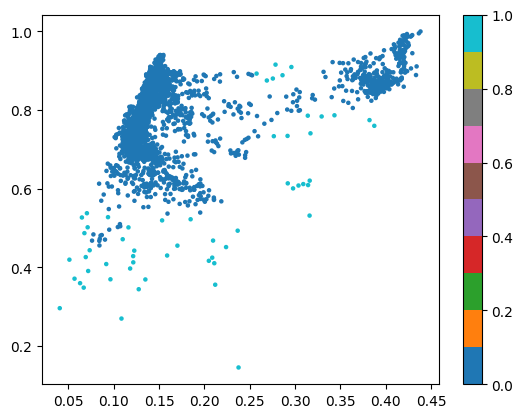

In [36]:
# gs = MinMaxScaler()
# df[['growth']] = gs.fit_transform(df[['growth']])
from MIOFlow.utils import kde

# Calculate density for each sample and filter out low density points
filtered_indices = []
for sample in df['samples'].unique():
    sample_data = df[df['samples']==sample]
    density = kde(sample_data[['d1', 'd2']])
    threshold = np.quantile(density, .02)
    filtered_indices.extend(sample_data[density >= threshold].index)
    
    # Visualization
    plt.scatter(sample_data['d1'], sample_data['d2'], c=density<threshold, s=5, cmap='tab10')
    plt.colorbar()
    plt.show()

# Update df to only include points above density threshold
df = df.loc[filtered_indices]

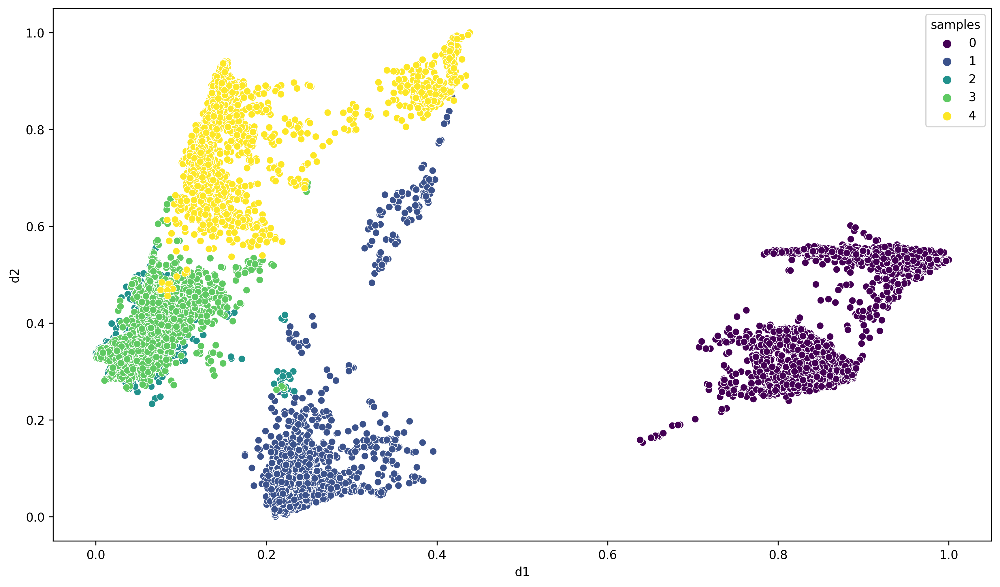

In [37]:
fig = plt.figure(figsize=(14, 8), dpi=300)
sns.scatterplot(data=df, x='d1', y='d2', hue='samples', palette='viridis');

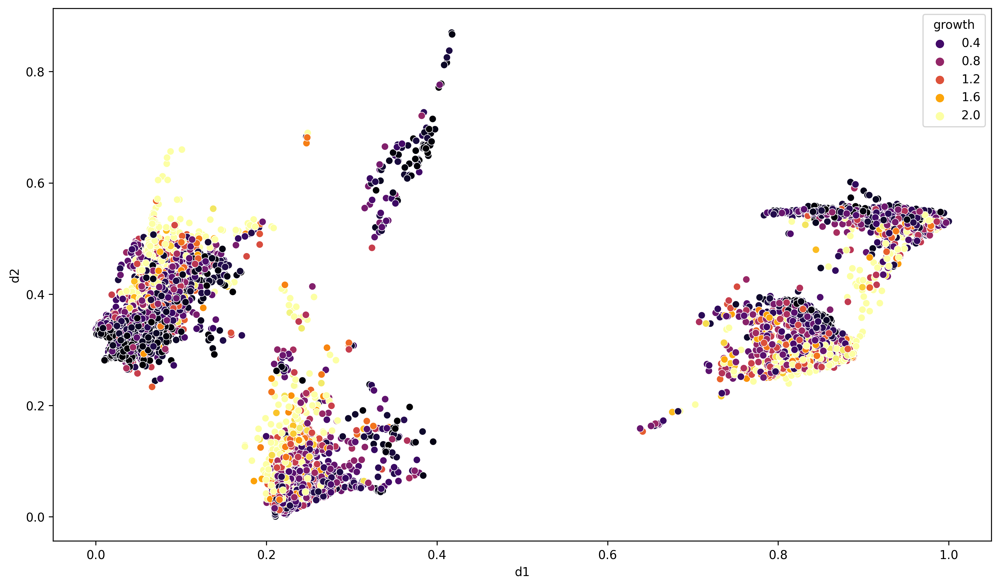

In [38]:
fig = plt.figure(figsize=(14, 8), dpi=300)
sns.scatterplot(data=df, x='d1', y='d2', hue='growth', palette='inferno');

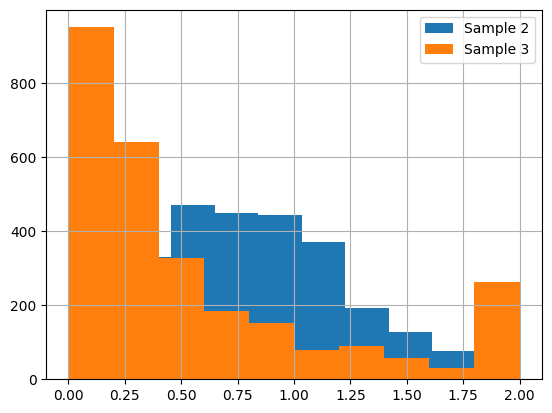

In [39]:
plt.figure()
df[df['samples'] == 2]['growth'].hist(label='Sample 2')
df[df['samples'] == 3]['growth'].hist(label='Sample 3')
plt.legend()

In [40]:
# Drop rows where samples == 3
df = df[df['samples'] != 3]
# # Map samples 0,1,2,4 to 0,1,2,3
# sample_map = {0:0, 1:1, 2:2, 4:3}
# df['samples'] = df['samples'].map(sample_map)


/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


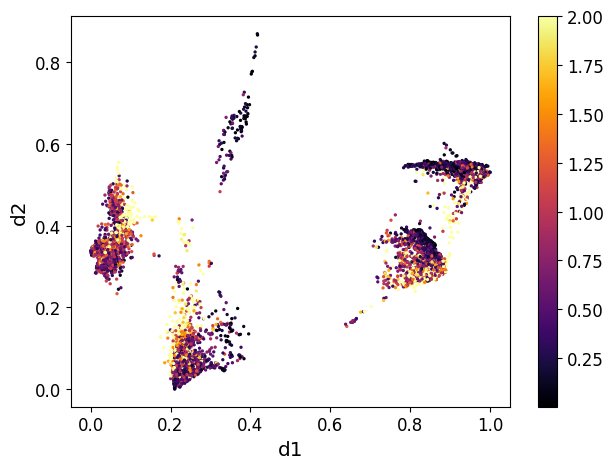

In [41]:
import scprep
scprep.plot.scatter2d(df[['d1', 'd2']], c=df['growth'], cmap='inferno');

In [42]:
df['samples'].value_counts()

samples
0    2775
1    2775
2    2775
4    2775
Name: count, dtype: int64

In [43]:
df

,d1,d2,samples,growth
0,0.936233,0.533404,0,0.091811
1,0.903360,0.551711,0,0.444972
2,0.879705,0.309708,0,0.188519
3,0.863476,0.342279,0,0.149393
4,0.876361,0.546400,0,0.150130
...,...,...,...,...
14155,0.110809,0.699623,4,NaN
14156,0.122427,0.733375,4,NaN
14157,0.150791,0.669738,4,NaN
14158,0.143723,0.863786,4,NaN


In [44]:
from MIOFlow.utils import sample
sample(df[['d1', 'd2', 'samples']], 0, size=2)
sample(df, 1, size=2)
# TODO should make sure the order is data, condition, growth_rate!
# TODO after that, in the train function, add the growth_rate_matching loss.

array([[0.23355224, 0.07416995, 0.62963391],
       [0.21081066, 0.01334772, 0.20260607]])

In [45]:
# from ot.unbalanced import sinkhorn_knopp_unbalanced
# def get_transform_matrix(gamma, a, epsilon=1e-8):
#     return (np.diag(1.0 / (a+ epsilon)) @ gamma).T

# def get_growth_coeffs(gamma, a, epsilon=1e-8, normalize=False):                                                                         
#     T = get_transform_matrix(gamma, a, epsilon)                                                                                         
#     unnormalized_coeffs = np.sum(T, axis=0)                                                                                             
#     if not normalize:                                                                                                                   
#         return unnormalized_coeffs                                                                                                      
#     return unnormalized_coeffs / np.sum(unnormalized_coeffs) * len(unnormalized_coeffs)   

# def calc_growth(source, target):
#     alpha = 2
#     a = adata.obsm['X_pca'][adata.obs['day'] == source]
#     b = adata.obsm['X_pca'][adata.obs['day'] == target]
#     m, n = a.shape[0], b.shape[0]
#     M = cdist(a,b)
#     entropy_reg = 0.1
#     reg_1, reg_2 = alpha, 10000
#     gamma = sinkhorn_knopp_unbalanced(np.ones(m) / m, np.ones(n) / n, M, entropy_reg, reg_1, reg_2)
#     return get_growth_coeffs(gamma, np.ones(m) / m)

In [46]:
# import ot
# data0 = df.loc[df['samples'] == 0, ['d1', 'd2']].values
# data1 = df.loc[df['samples'] == 1, ['d1', 'd2']].values
# m = ot.unif(len(data0))
# n = ot.unif(len(data1))
# M = ot.dist(data0, data1)
# reg_m_l2 = [1., 1.]
# plan = ot.unbalanced.mm_unbalanced(m, n, M, reg_m_l2, div='l2')


In [47]:
# centroids = df.groupby('samples')[['d1', 'd2']].mean()
# centroid_distances = centroids.diff().dropna().apply(lambda row: np.linalg.norm(row), axis=1)

# # Revalue the samples column
# new_samples = [0]
# for distance in centroid_distances:
#     new_samples.append(new_samples[-1] + distance)
# df['samples'] = df['samples'].map(dict(zip(df['samples'].unique(), new_samples)))

In [48]:
# fig = plt.figure(figsize=(14, 8), dpi=300)
# sns.scatterplot(data=df, x='d1', y='d2', hue='samples', palette='viridis');

In [49]:
# scatter = plt.scatter(df['d1'], df['d2'], c=df['samples'], cmap='viridis', s=1, alpha=.5)
# # plt.colorbar(scatter, label='Samples')
# plt.legend(title='Samples', handles=[plt.scatter([], [], c=c, label=np.round(df['samples'].unique()[i], 2)) for i, c in enumerate(plt.cm.viridis(np.linspace(0, 1, len(df['samples'].unique()))))], loc='center left', bbox_to_anchor=(0.8, 0.8))
# plt.scatter(centroids['d1'], centroids['d2'], c='red', s=10, alpha=1)
# plt.tight_layout()
# plt.show()

# Train autoencoder or the geodesic embedding

#### Set seeds and check GPU

In [50]:
set_seeds(0)
use_cuda = torch.cuda.is_available()

#### Handle hold-out training condition

In [51]:
# This is True if we want to holdout (or skip) one timepoint during training. It is used to test the accuracy of the trajectories on unseen data.
hold_one_out = False
# It can be a group number or 'random', works in tandem with hold_one_out
hold_out = 3

# The dimensions in the input space, it is columns - 1 because we assume one column is equal to "samples".
model_features = len(df.columns) - 1 - 1 # remove the sample col and the growth rate col
groups = sorted(df.samples.unique())

In [52]:
# These determine the logic flow for training: 
#   use_emb=True use_gae=False is only the encoder to match the approximation of the geodesic.
#   use_emb=False use_gae=True the full Geodesic Autoencoder (GAE), i.e. matching the geodesic and a reconstruction loss.
#   use_emb=False use_gae=False Is not using the GAE.
#   use_emb=True use_gae=True, is redundant and should raise an error. 
use_emb = False
use_gae = False

need_to_train_gae = (use_emb or use_gae) and use_emb != use_gae

# If the reconstruction loss needs to be computed.
recon = use_gae and not use_emb 

# These are training GAE hyperparameters needed for training
# Distance_type in ['gaussian', 'alpha_decay'], and Gaussian scale
distance_type = 'gaussian'
rbf_length_scale=0.1
dist = setup_distance(distance_type, rbf_length_scale=rbf_length_scale)

#Can be changed depending on the dataset
n_epochs_emb = 1000
samples_size_emb = (30, )

# Layers for the Geodesic Autoencoder
gae_embedded_dim = 32
encoder_layers = [model_features, 8, gae_embedded_dim]

gae = Autoencoder(
    encoder_layers = encoder_layers,
    decoder_layers = encoder_layers[::-1],
    activation='ReLU', use_cuda = use_cuda
)
optimizer = torch.optim.AdamW(gae.parameters())

#### Actually train the GAE

In [53]:
# Added in extra cell just for iterative programming / running of code
#   but could be added to code block above

if need_to_train_gae:
    start_time_geo = time.time()

    losses = train_ae(
        gae, df, groups, optimizer, 
        n_epochs=n_epochs_emb, sample_size=samples_size_emb,
        noise_min_scale=0.09, noise_max_scale=0.15, 
        dist=dist, recon=recon, use_cuda=use_cuda,
        hold_one_out=hold_one_out, hold_out=hold_out
    )
    run_time_geo = time.time() - start_time_geo

    print(run_time_geo)
    autoencoder = gae
else:
    autoencoder = None

# Specify parameters

In [54]:
set_seeds(10)

#Directory where results are saved
exp_name = 'test'

# density loss knn
use_density_loss = True

# Weight of density (not percentage of total loss)
lambda_density = 35

# For petal=LeakyReLU / dyngen=CELU
activation = 'LeakyReLU'

# Can change but we never really do, mostly depends on the dataset.
layers = [16,32,16]

# Scale of the noise in the trajectories. Either len(groups)*[float] or None. Should be None if using an adaptative ODE solver.
sde_scales = len(groups)*[0.1] 

if recon:    
    model_features = gae_embedded_dim

model = make_model(
    model_features, layers, 
    activation=activation, scales=sde_scales, use_cuda=use_cuda,
    # which='sde_growth_rate',
    which='ode_growth_rate_sep',
    # m_transform='exp', # TODO try relu and exp
    m_transform='relu', # TODO try relu and exp
    # method='euler',
    time_homogeneous=True,
    unif_velo=True,
    separate_network_m=True,
)

In [55]:
# Basically "batch size"
sample_size=(50, )

# Training specification
# n_local_epochs = 20
n_local_epochs = 40
# n_epochs = 20
n_epochs = 0
n_post_local_epochs = 0

# Using the reverse trajectories to train
reverse_schema = False
# reverse_schema = False 
# each reverse_n epoch
reverse_n = 2


# criterion_name = 'ot'
# criterion_name = 'density_specified_ot'
# criterion = config_criterion(criterion_name, reg=0.2, detach_M_ot=False)
# print(criterion.detach_M_ot)

optimizer = torch.optim.AdamW(model.parameters())

# Bookkeeping variables
batch_losses = []
globe_losses = []
if hold_one_out and hold_out in groups:
    local_losses = {f'{t0}:{t1}':[] for (t0, t1) in generate_steps(groups) if hold_out not in [t0, t1]}
else:
    local_losses = {f'{t0}:{t1}':[] for (t0, t1) in generate_steps(groups)}

# For creating output.
n_points = 50
n_trajectories = 50
n_bins = 100


In [56]:
opts = {
    'phate_dims': phate_dims,
    'use_cuda': use_cuda,
    'model_features': model_features,
    'exp_name': exp_name,
    'groups': groups,
    'sample_size': sample_size,
    'use_emb': use_emb,
    'n_local_epochs': n_local_epochs,
    'n_epochs': n_epochs,
    'n_post_local_epochs': n_post_local_epochs,
    # 'criterion_name': criterion_name,
    'hold_one_out': hold_one_out,
    'use_density_loss': use_density_loss,
    'n_points': n_points,
    'n_trajectories': n_trajectories,
    'n_bins': n_bins,
    'autoencoder': autoencoder,
    'activation_ode': activation,
    'layer': layers,
    'lambda_density':lambda_density,
    'use_gae': use_gae,
    'sde_scales': sde_scales,
    'hold_out':hold_out,
    'encoder_layers': encoder_layers,
    'n_epochs_emb': n_epochs_emb,
    'samples_size_emb': samples_size_emb,
    'recon': recon,
    'distance_type':distance_type,
    'rbf_length_scale':rbf_length_scale,
    'reverse_schema': reverse_schema,
    'reverse_n': reverse_n
}

In [57]:
exp_dir, logger = setup_exp(RES_DIR, opts, exp_name) 

In [70]:
def train_growth_rate(m_net, x_tensor, g_tensor, optimizer, n_epochs, batch_size=32, use_cuda=False):
    """Train the MNet model using input x tensor and target y tensor with batch SGD"""
    criterion = nn.MSELoss()
    losses = []
    
    if use_cuda:
        m_net = m_net.cuda()
        x_tensor = x_tensor.cuda()
        g_tensor = g_tensor.cuda()
    
    # Create dataset and dataloader
    dataset = torch.utils.data.TensorDataset(x_tensor, g_tensor)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    # Training loop
    pbar = tqdm(range(n_epochs), desc='Training')
    for epoch in pbar:
        m_net.train()
        epoch_loss = 0
        
        for batch_x, batch_g in dataloader:
            optimizer.zero_grad()
            
            # Forward pass
            output = m_net(batch_x)
            
            # Calculate loss
            loss = criterion(output, batch_g)
            epoch_loss += loss.item()
            
            # Backward pass and optimize
            loss.backward()
            optimizer.step()
        
        # Average loss for epoch
        avg_epoch_loss = epoch_loss / len(dataloader)
        losses.append(avg_epoch_loss)
        
        # Update progress bar with current loss
        pbar.set_postfix({'loss': f'{avg_epoch_loss:.4f}'})
    
    return losses

model = make_model(
    model_features, layers, 
    activation=activation, scales=sde_scales, use_cuda=use_cuda,
    # which='sde_growth_rate',
    which='ode_growth_rate_sep',
    # m_transform='exp', # TODO try relu and exp
    m_transform='relu', # TODO try relu and exp
    # method='euler',
    time_homogeneous=True,
    unif_velo=True,
    separate_network_m=True,
)

# Train the model
# x_tensor = torch.tensor(df.loc[df['samples'] == 0, ['d1', 'd2']].values, dtype=torch.float32)
# g_tensor = torch.tensor(df.loc[df['samples'] == 0, 'growth'].values, dtype=torch.float32)
x_tensor = torch.tensor(df.loc[df['samples'] != df['samples'].max(), ['d1', 'd2']].values, dtype=torch.float32)
g_tensor = torch.tensor(df.loc[df['samples'] != df['samples'].max(), 'growth'].values, dtype=torch.float32)
m_optimizer = torch.optim.AdamW(model.m_net.parameters(), lr=0.001)
n_epochs_m = 100
losses_m = train_growth_rate(model.m_net, x_tensor, g_tensor, m_optimizer, n_epochs_m, batch_size=32, use_cuda=use_cuda)


Training:   0%|          | 0/100 [00:00<?, ?it/s]

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([32])) that is different to the input size (torch.Size([32, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([5])) that is different to the input size (torch.Size([5, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


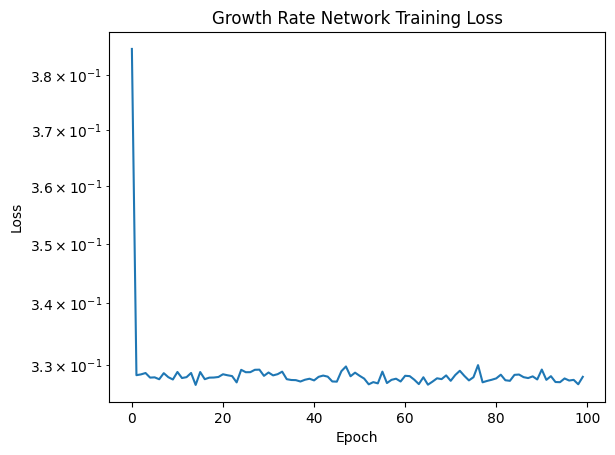

In [71]:
plt.figure()
plt.plot(losses_m)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.yscale('log')
plt.title('Growth Rate Network Training Loss')
plt.show()

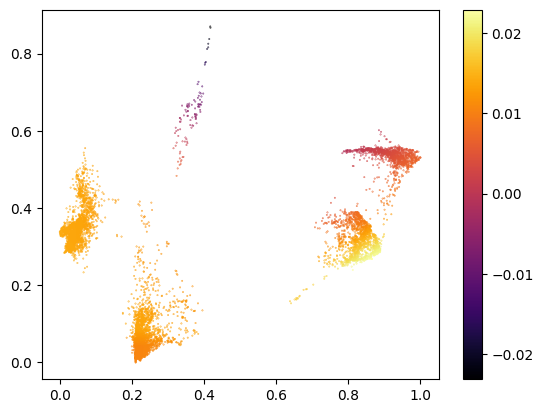

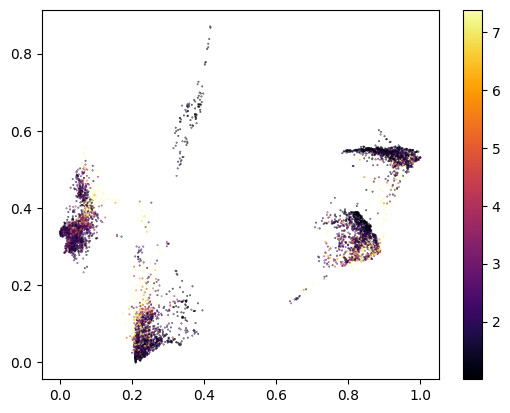

In [75]:
# data_pts = df.loc[df['samples'] != df['samples'].max(),['d1', 'd2']].values
# data_pts = torch.tensor(data_pts, dtype=torch.float32)
data_pts = x_tensor
with torch.no_grad():
    ms = model.m_net(data_pts)
    m_pred = ms.squeeze(-1).cpu().numpy()
    # m_pred = gs.inverse_transform(m_pred.reshape(-1, 1))
plt.figure()
plt.scatter(data_pts[:,0], data_pts[:,1], c=m_pred-0.86, s=.1, cmap='inferno')
plt.colorbar()
plt.show()

plt.figure()
plt.scatter(data_pts[:,0], data_pts[:,1], c=torch.exp(g_tensor).squeeze(-1).cpu().numpy(), s=.1, cmap='inferno')
plt.colorbar()
plt.show()

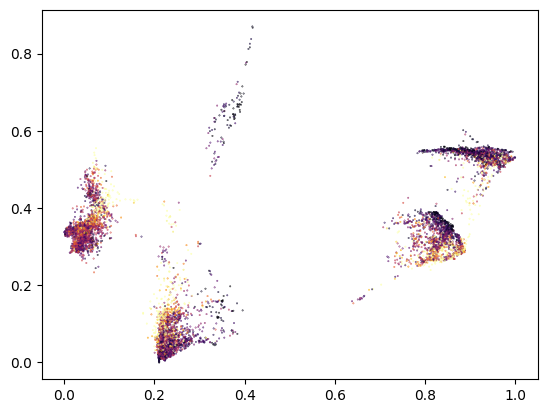

In [73]:
plt.scatter(x_tensor[:,0].cpu().numpy(), x_tensor[:,1].cpu().numpy(), c=g_tensor.cpu().numpy(), s=.1, cmap='inferno')

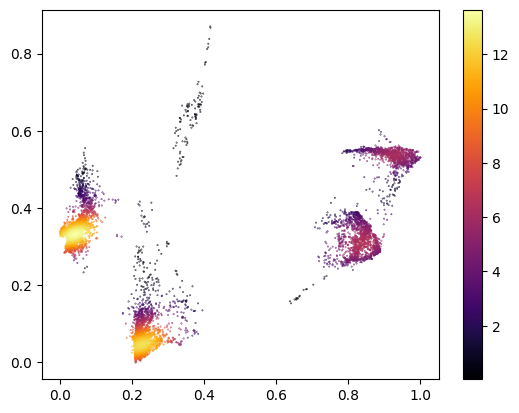

In [74]:
density = kde(x_tensor)
plt.scatter(x_tensor[:,0].cpu().numpy(), x_tensor[:,1].cpu().numpy(), c=density.cpu().numpy(), s=.1, cmap='inferno')
plt.colorbar()
plt.show()

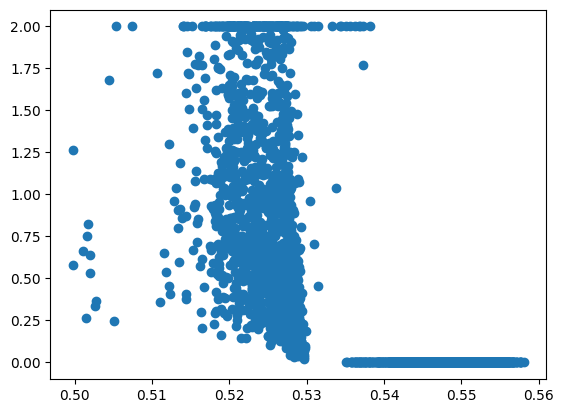

In [243]:
plt.scatter(ms.squeeze(-1).cpu().numpy(), g_tensor.cpu().numpy())
plt.show()


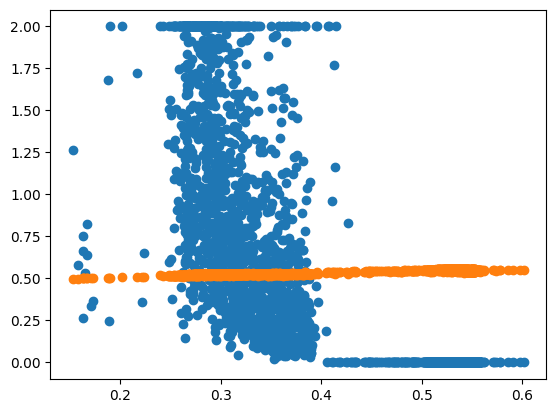

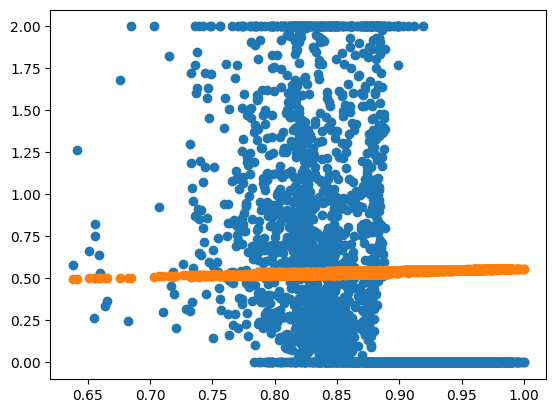

In [247]:
plt.scatter(x_tensor[:,1].cpu().numpy(), g_tensor.cpu().numpy())
plt.scatter(x_tensor[:,1].cpu().numpy(), m_pred)
plt.show()
plt.scatter(x_tensor[:,0].cpu().numpy(), g_tensor.cpu().numpy())
plt.scatter(x_tensor[:,0].cpu().numpy(), m_pred)
plt.show()


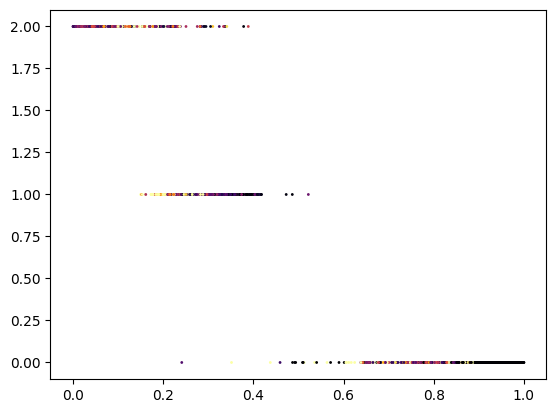

In [141]:
# plt.scatter(df['d1'], df['growth'])
# plt.scatter(df['d2'], df['growth'])
# plt.scatter(df['samples'], df['growth'])
plt.scatter(df['d1'], df['samples'], c=df['growth'], s=1, cmap='inferno')
plt.show()


In [101]:
# def kernel_smooth_2d(x_train, y_train, x_test, bandwidth=None):
#     """
#     Perform kernel smoothing for 2D input data and 1D output using statsmodels with Scott's rule
    
#     Args:
#         x_train: Training input points (N x 2 array)
#         y_train: Training output values (N array) 
#         x_test: Test input points to predict (M x 2 array)
#         bandwidth: Optional bandwidth parameter, if None uses Scott's rule
        
#     Returns:
#         y_pred: Predicted values at test points (M array)
#     """
#     # Convert inputs to numpy if needed
#     if torch.is_tensor(x_train):
#         x_train = x_train.detach().cpu().numpy()
#     if torch.is_tensor(y_train):
#         y_train = y_train.detach().cpu().numpy()
#     if torch.is_tensor(x_test):
#         x_test = x_test.detach().cpu().numpy()
        
#     # Use statsmodels KernelReg with Scott's rule for bandwidth
#     from statsmodels.nonparametric.kernel_regression import KernelReg
#     kr = KernelReg(endog=y_train, exog=x_train, var_type='cc', bw='scott')
#     y_pred = kr.fit(x_test)[0]
        
#     return y_pred

# df_subsample = df.sample(n=3000, random_state=42)

# x_tensor = torch.tensor(df_subsample.loc[df_subsample['samples'] != df_subsample['samples'].max(), ['d1', 'd2']].values, dtype=torch.float32)
# g_tensor = torch.tensor(df_subsample.loc[df_subsample['samples'] != df_subsample['samples'].max(), 'growth'].values, dtype=torch.float32)
# g_smooth = kernel_smooth_2d(x_tensor, g_tensor, x_tensor)

# plt.figure()
# plt.scatter(x_tensor[:,0], x_tensor[:,1], c=g_tensor, s=1, cmap='inferno')
# plt.colorbar()
# plt.show()


In [102]:
# plt.figure()
# plt.scatter(x_tensor[:,0], x_tensor[:,1], c=g_smooth, s=1, cmap='inferno')
# plt.colorbar()
# plt.show()

In [127]:
"""
'Pretraining' -- with a large penalty on m being non-constant, to stablize the trajectories
"""
criterion = UOT_loss(reg_m_l2=[10., 10.], detach_M=True, detach_m=True, use_uniform=False) # large penalty on matching target mass
# criterion = UOT_loss(reg_m_l2=[1., 1.], detach_M=True, detach_m=True, use_uniform=True) # large penalty on matching target mass
start_time = time.time()
local_losses, batch_losses, globe_losses, losses_dict = training_regimen(
    # local, global, local train structure
    n_local_epochs=40, 
    n_epochs=0, 
    n_post_local_epochs=n_post_local_epochs,
    n_batches=5,
    # where results are stored
    exp_dir=exp_dir, 

    # BEGIN: train params
    model=model, df=df, groups=groups, optimizer=optimizer, 
    criterion=criterion, use_cuda=use_cuda,
    
    hold_one_out=hold_one_out, hold_out=hold_out,
    
    use_density_loss=use_density_loss, density_detach_m=False,
    lambda_density=35.,
    # lambda_density=100.,
    
    autoencoder=autoencoder, use_emb=use_emb, use_gae=use_gae, 
    
    sample_size=sample_size, logger=logger,
    reverse_schema=False, reverse_n=1,
    use_penalty=False, lambda_energy=10.,
    use_penalty_m=False, lambda_energy_m=0.,
    lambda_m=0., lambda_m2=0.,
    lambda_ot=10., lambda_marginal=0.,
    energy_weighted=True,
    energy_detach_m=False,

    # regularizations for diffusion term
    diffusion_lambda_energy=.0,
    diffusion_lambda_energy_m=.0,
    diffusion_energy_weighted=True,
    diffusion_energy_detach_m=False,

    # END: train params

    plot_every=None,
    n_points=n_points, n_trajectories=n_trajectories, n_bins=n_bins, 
    #local_losses=local_losses, batch_losses=batch_losses, globe_losses=globe_losses
    use_kde=False,

    lambda_unif_velo=1.,
    unif_velo_weighted=False,
    unif_velo_detach_m=True,
    unif_velo_square=True,
    unif_velo_topk=1,
    growth_reg=True,
    growth_reg_lambda=10.,
)
run_time = time.time() - start_time + run_time_geo if use_emb or use_gae else time.time() - start_time
logger.info(f'Total run time: {np.round(run_time, 5)}')

Pretraining Epoch:   0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

...

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0it [00:00, ?it/s]

Posttraining Epoch: 0it [00:00, ?it/s]

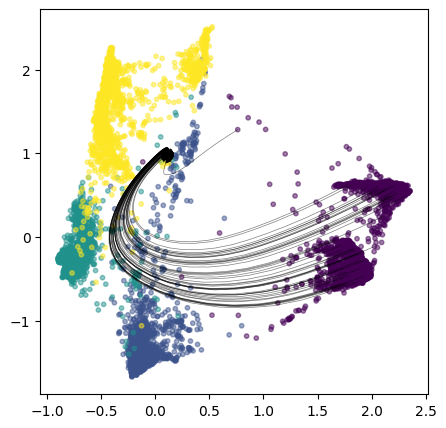

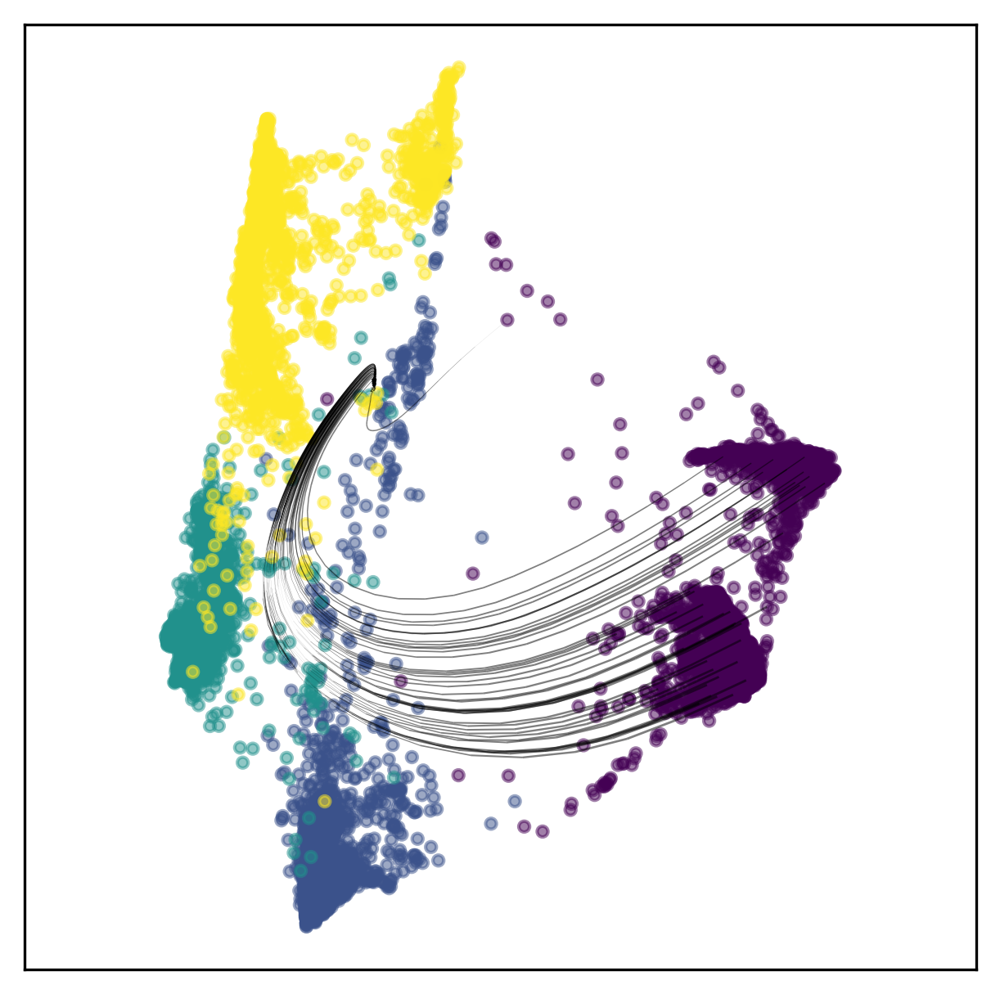

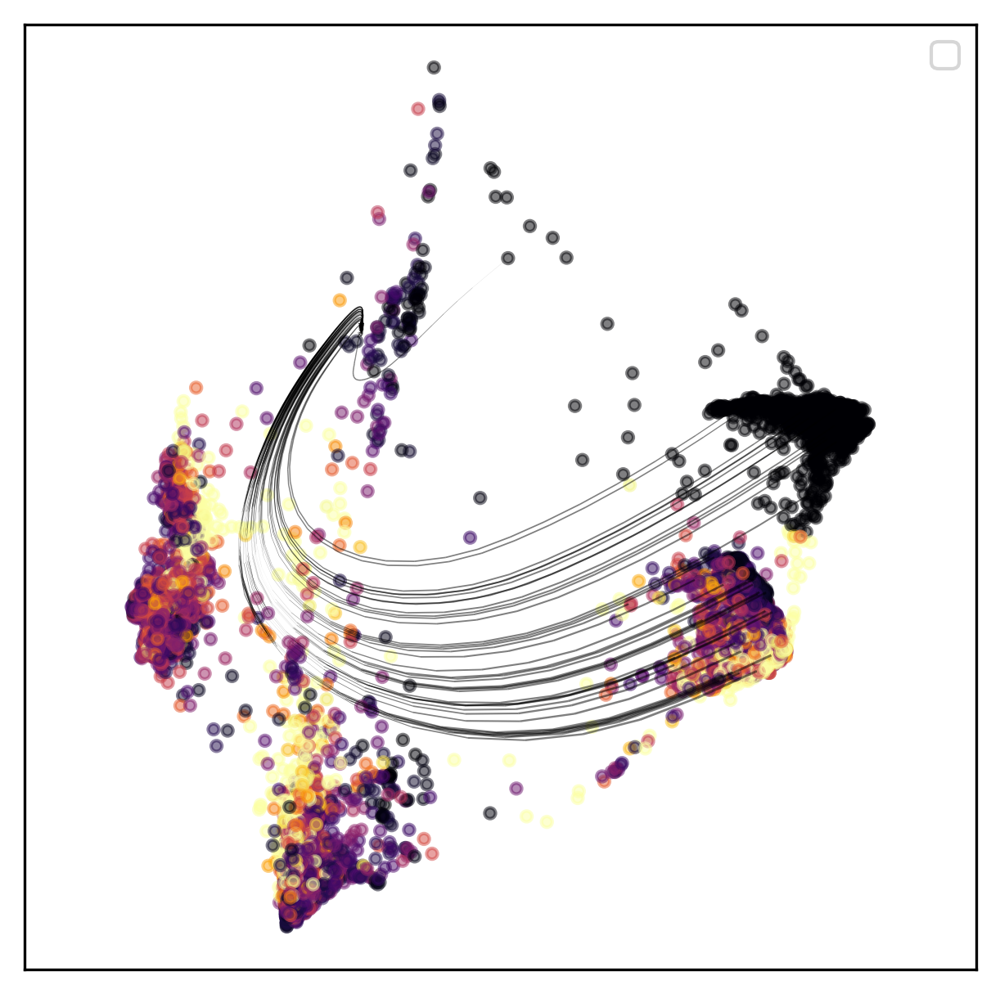

In [128]:
np.random.seed(32)
groups = sorted(df['samples'].unique())
sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
from MIOFlow.utils import sample
data_t0 = sample(
    df, np.min(groups), size=(n_points, ), 
    replace=False, to_torch=True, use_cuda=use_cuda
)
data_t0 = data_t0[:,:-1]
sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

from MIOFlow.losses import hard_softmax
# threshold_factor = 0.3
with torch.no_grad():
    x_traj, m_traj = model(data_t0, sample_time, return_whole_sequence=True)
    m_traj0 = m_traj
    # m_traj = torch.exp(m_traj)
    # m_traj1 = m_traj
    # threshold = 0.3
    # m_traj2 = torch.nn.functional.sigmoid(m_traj)
    # m_traj2 = torch.where(m_traj2 < threshold, torch.zeros_like(m_traj2), m_traj2)
# threshold = threshold_factor * m_traj.mean(dim=-1, keepdim=True)
# m_traj = torch.where(m_traj <= threshold, torch.tensor(0., dtype=m_traj.dtype, device=m_traj.device), m_traj)
# m_traj = hard_softmax(m_traj, dim=-1)
# m_traj2 = nn.functional.softmax(m_traj0, dim=-1)
x_traj = x_traj.cpu().numpy()
# m_traj_softmax = nn.functional.softmax(m_traj0, dim=-1).cpu().numpy()
m_traj0 = m_traj0.cpu().numpy()
# threshold = 1/m_traj.shape[-1]
# m_traj[m_traj < threshold] = 0.
# m_traj = m_traj / m_traj.max()
m_traj = m_traj.cpu().numpy()
# m_traj1 = m_traj1.cpu().numpy()
# m_traj = np.exp(m_traj)
# m_traj = m_traj / m_traj[0,0]
# m_traj3 = m_traj1 / m_traj1.max()


# plt.figure()
# for i in range(n_points):
#     plt.plot(sample_time.cpu().numpy(), m_traj0[:,i], c='black', alpha=0.1)
#     plt.title('masses')


# plt.figure()
# for i in range(n_points):
#     plt.plot(sample_time.cpu().numpy(), m_traj1[:,i], c='black', alpha=0.1)
#     plt.title('unnormalized probabilities')

# plt.figure()
# for i in range(n_points):
#     plt.plot(sample_time.cpu().numpy(), m_traj_softmax[:,i], c='black', alpha=0.1)
#     plt.title('softmax probabilities')


# plt.figure()
# for i in range(n_points):
#     plt.plot(sample_time.cpu().numpy(), m_traj[:,i], c='black', alpha=0.1)
#     plt.title('probabilities thresholded')

plt.figure(figsize=(5, 5))
plt.scatter(df['d1'], df['d2'],
                c=df['samples'] , cmap='viridis', s=10, alpha=.5)
for i,traj in enumerate(np.transpose(x_traj, axes=(1,0,2))):
    widths = m_traj[:,i]
    plt.plot(traj[:, 0], traj[:, 1], alpha=.5, linewidth=.5, color='Black');
    plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
                 arrowprops=dict(arrowstyle="-|>", color='Black', lw=.1))

from matplotlib.collections import LineCollection

# m_trajt = m_traj_softmax/ m_traj_softmax.max()
m_trajt = m_traj
# when m_
plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(df['d1'], df['d2'],
                c=df['samples'] , cmap='viridis', s=10, alpha=.5)
subsampled_points = np.random.choice(x_traj.shape[1], 40, replace=False)
for i in subsampled_points:
    # Use the width array to determine the linewidths for this trajectory
    traj = x_traj[:,i,:]
    linewidths = m_trajt[:,i] * 2
    
    # Create segments for the trajectory
    segments = [np.array([traj[j], traj[j+1]]) for j in range(len(traj)-1)]
    
    # Create a LineCollection with the segments and the corresponding linewidths
    lc = LineCollection(segments, linewidths=linewidths, color='black', alpha=0.5)
    plt.gca().add_collection(lc)

    # Add the arrow at the end of the trajectory
    # plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
    #              arrowprops=dict(arrowstyle="-|>", color='Black', lw=.05))
# Autoscale to adjust plot limits
plt.gca().autoscale()
plt.xticks([])  # Hides x-axis ticks
plt.yticks([])  # Hides y-axis ticks
plt.axis('equal')

plt.show()


plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(df['d1'], df['d2'],
                c=df['growth'] , cmap='inferno', s=10, alpha=.5)
subsampled_points = np.random.choice(x_traj.shape[1], 40, replace=False)
for i in subsampled_points:
    # Use the width array to determine the linewidths for this trajectory
    traj = x_traj[:,i,:]
    linewidths = m_trajt[:,i] * 2
    
    # Create segments for the trajectory
    segments = [np.array([traj[j], traj[j+1]]) for j in range(len(traj)-1)]
    
    # Create a LineCollection with the segments and the corresponding linewidths
    lc = LineCollection(segments, linewidths=linewidths, color='black', alpha=0.5)
    plt.gca().add_collection(lc)

    # Add the arrow at the end of the trajectory
    # plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
    #              arrowprops=dict(arrowstyle="-|>", color='Black', lw=.05))
# Autoscale to adjust plot limits
plt.legend()
plt.gca().autoscale()
plt.xticks([])  # Hides x-axis ticks
plt.yticks([])  # Hides y-axis ticks
plt.axis('equal')

plt.show()


In [129]:
# np.random.seed(32)
# groups = sorted(df['samples'].unique())
# sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
# from MIOFlow.utils import sample
# data_t0 = sample(
#     df, np.min(groups), size=(n_points, ), 
#     replace=False, to_torch=True, use_cuda=use_cuda
# )
# data_t0 = data_t0[:,:-1]
# sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

# from MIOFlow.losses import hard_softmax
# # threshold_factor = 0.3
# with torch.no_grad():
#     x_traj, m_traj = model(data_t0, sample_time, return_whole_sequence=True)
#     m_traj0 = m_traj
#     # m_traj = torch.exp(m_traj)
#     # m_traj1 = m_traj
#     # threshold = 0.3
#     # m_traj2 = torch.nn.functional.sigmoid(m_traj)
#     # m_traj2 = torch.where(m_traj2 < threshold, torch.zeros_like(m_traj2), m_traj2)
# # threshold = threshold_factor * m_traj.mean(dim=-1, keepdim=True)
# # m_traj = torch.where(m_traj <= threshold, torch.tensor(0., dtype=m_traj.dtype, device=m_traj.device), m_traj)
# # m_traj = hard_softmax(m_traj, dim=-1)
# # m_traj2 = nn.functional.softmax(m_traj0, dim=-1)
# x_traj = x_traj.cpu().numpy()
# # m_traj_softmax = nn.functional.softmax(m_traj0, dim=-1).cpu().numpy()
# m_traj0 = m_traj0.cpu().numpy()
# # threshold = 1/m_traj.shape[-1]
# # m_traj[m_traj < threshold] = 0.
# # m_traj = m_traj / m_traj.max()
# m_traj = m_traj.cpu().numpy()
# # m_traj1 = m_traj1.cpu().numpy()
# # m_traj = np.exp(m_traj)
# # m_traj = m_traj / m_traj[0,0]
# # m_traj3 = m_traj1 / m_traj1.max()


# plt.figure()
# for i in range(n_points):
#     plt.plot(sample_time.cpu().numpy(), m_traj0[:,i], c='black', alpha=0.1)
#     plt.title('masses')


# # plt.figure()
# # for i in range(n_points):
# #     plt.plot(sample_time.cpu().numpy(), m_traj1[:,i], c='black', alpha=0.1)
# #     plt.title('unnormalized probabilities')

# # plt.figure()
# # for i in range(n_points):
# #     plt.plot(sample_time.cpu().numpy(), m_traj_softmax[:,i], c='black', alpha=0.1)
# #     plt.title('softmax probabilities')


# # plt.figure()
# # for i in range(n_points):
# #     plt.plot(sample_time.cpu().numpy(), m_traj[:,i], c='black', alpha=0.1)
# #     plt.title('probabilities thresholded')

# plt.figure(figsize=(5, 5))
# plt.scatter(df['d1'], df['d2'],
#                 c=df['samples'] , cmap='viridis', s=10, alpha=.5)
# for i,traj in enumerate(np.transpose(x_traj, axes=(1,0,2))):
#     widths = m_traj[:,i]
#     plt.plot(traj[:, 0], traj[:, 1], alpha=.5, linewidth=.5, color='Black');
#     plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
#                  arrowprops=dict(arrowstyle="-|>", color='Black', lw=.1))

# from matplotlib.collections import LineCollection

# # m_trajt = m_traj_softmax/ m_traj_softmax.max()
# m_trajt = m_traj
# # when m_
# plt.figure(figsize=(5, 5), dpi=300)
# plt.scatter(df['d1'], df['d2'],
#                 c=df['samples'] , cmap='viridis', s=10, alpha=.5)
# subsampled_points = np.random.choice(x_traj.shape[1], 40, replace=False)
# for i in subsampled_points:
#     # Use the width array to determine the linewidths for this trajectory
#     traj = x_traj[:,i,:]
#     linewidths = m_trajt[:,i] * 2
    
#     # Create segments for the trajectory
#     segments = [np.array([traj[j], traj[j+1]]) for j in range(len(traj)-1)]
    
#     # Create a LineCollection with the segments and the corresponding linewidths
#     lc = LineCollection(segments, linewidths=linewidths, color='black', alpha=0.5)
#     plt.gca().add_collection(lc)

#     # Add the arrow at the end of the trajectory
#     # plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
#     #              arrowprops=dict(arrowstyle="-|>", color='Black', lw=.05))
# # Autoscale to adjust plot limits
# plt.gca().autoscale()
# plt.xticks([])  # Hides x-axis ticks
# plt.yticks([])  # Hides y-axis ticks
# plt.axis('equal')

# plt.show()


# # m_trajt = m_traj2/ m_traj2.max()
# # # m_trajt[m_trajt < 0.4] = 0
# # # when m_
# # plt.figure(figsize=(5, 5), dpi=300)
# # plt.scatter(df['d1'], df['d2'],
# #                 c=df['samples'] , cmap='viridis', s=10, alpha=.5)
# # subsampled_points = np.random.choice(x_traj.shape[1], 40, replace=False)
# # for i in subsampled_points:
# #     # Use the width array to determine the linewidths for this trajectory
# #     traj = x_traj[:,i,:]
# #     linewidths = m_trajt[:,i] * 2
    
# #     # Create segments for the trajectory
# #     segments = [np.array([traj[j], traj[j+1]]) for j in range(len(traj)-1)]
    
# #     # Create a LineCollection with the segments and the corresponding linewidths
# #     lc = LineCollection(segments, linewidths=linewidths, color='black', alpha=0.5)
# #     plt.gca().add_collection(lc)

# #     # Add the arrow at the end of the trajectory
# #     # plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
# #     #              arrowprops=dict(arrowstyle="-|>", color='Black', lw=.05))
# # # Autoscale to adjust plot limits
# # plt.gca().autoscale()
# # plt.xticks([])  # Hides x-axis ticks
# # plt.yticks([])  # Hides y-axis ticks
# # plt.axis('equal')

# # plt.show()

# # m_trajt = m_traj
# # m_trajt[m_trajt < 0.7] = 0
# # m_trajt = m_trajt/ m_trajt.max()
# # # when m_
# # plt.figure(figsize=(5, 5), dpi=300)
# # plt.scatter(df['d1'], df['d2'],
# #                 c=df['samples'] , cmap='viridis', s=10, alpha=.5)
# # subsampled_points = np.random.choice(x_traj.shape[1], 40, replace=False)
# # for i in subsampled_points:
# #     # Use the width array to determine the linewidths for this trajectory
# #     traj = x_traj[:,i,:]
# #     linewidths = m_trajt[:,i] * 2
    
# #     # Create segments for the trajectory
# #     segments = [np.array([traj[j], traj[j+1]]) for j in range(len(traj)-1)]
    
# #     # Create a LineCollection with the segments and the corresponding linewidths
# #     lc = LineCollection(segments, linewidths=linewidths, color='black', alpha=0.5)
# #     plt.gca().add_collection(lc)

# #     # Add the arrow at the end of the trajectory
# #     # plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
# #     #              arrowprops=dict(arrowstyle="-|>", color='Black', lw=.05))
# # # Autoscale to adjust plot limits
# # plt.gca().autoscale()
# # plt.xticks([])  # Hides x-axis ticks
# # plt.yticks([])  # Hides y-axis ticks
# # plt.axis('equal')

# # plt.show()

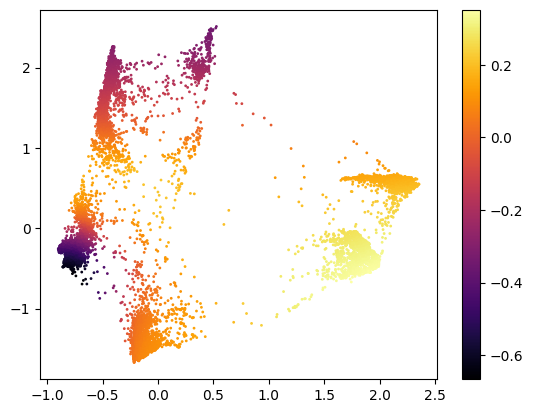

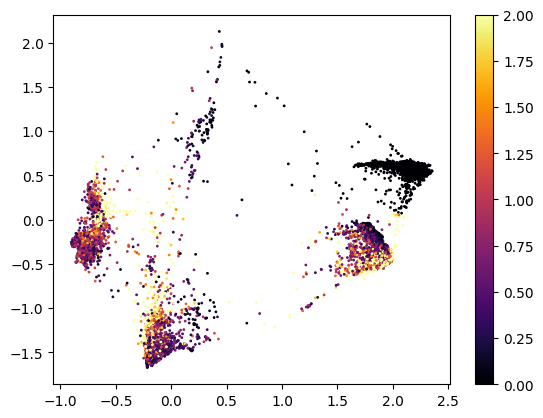

In [130]:
data_pts = df[['d1', 'd2']].values
data_pts = torch.tensor(data_pts, dtype=torch.float32)
with torch.no_grad():
    ms = model.m_net(data_pts)
plt.figure()
plt.scatter(data_pts[:,0], data_pts[:,1], c=ms.squeeze(-1).cpu().numpy(), s=1, cmap='inferno')
plt.colorbar()
plt.show()

plt.figure()
plt.scatter(df['d1'], df['d2'], c=df['growth'], s=1, cmap='inferno')
plt.colorbar()
plt.show()

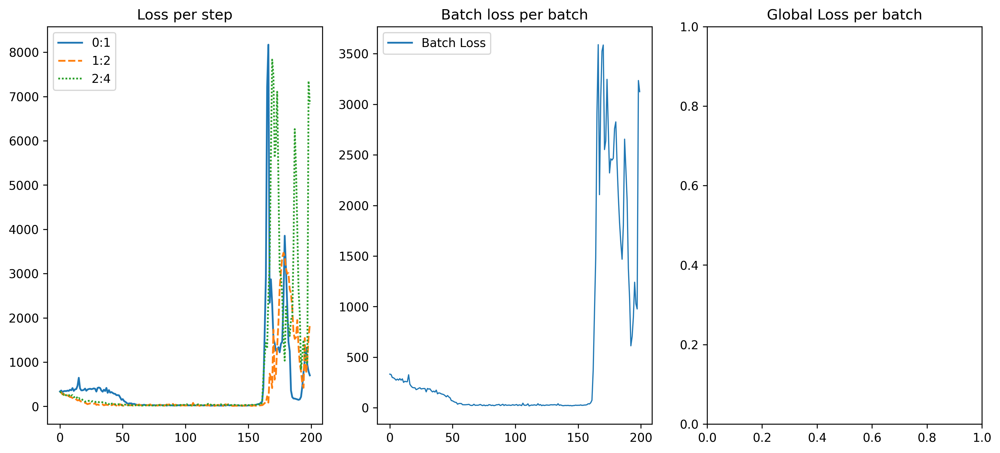

In [131]:
plot_losses(
    local_losses, batch_losses, globe_losses, 
    save=False,
)


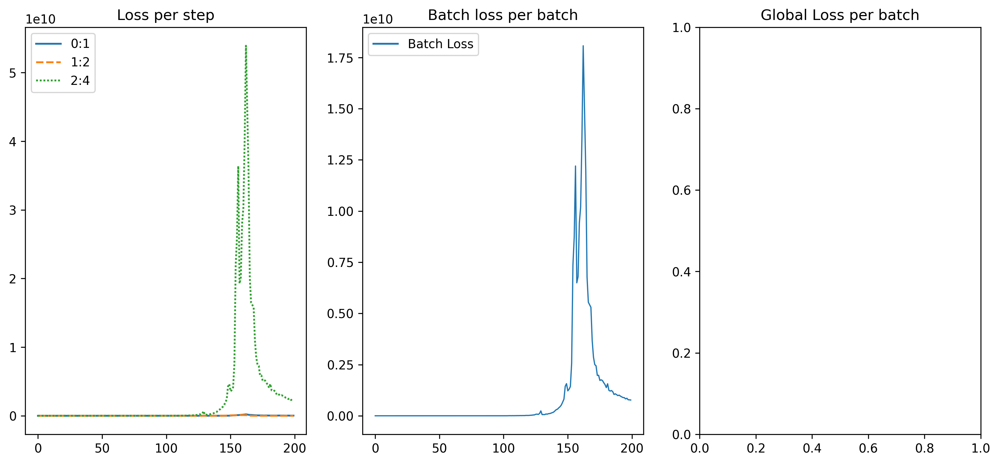

In [122]:
plot_losses(
    local_losses, batch_losses, globe_losses, 
    save=False,
)


In [123]:
with torch.no_grad():
    xtseq, mtseq = model(data_t0, sample_time, return_whole_sequence=True)
    xmseq = torch.cat([xtseq, mtseq.unsqueeze(-1)], dim=-1)
    dxdt = torch.stack([model.func(sample_time[i], xmseq[i]) for i in range(len(sample_time))])

RuntimeError: mat1 and mat2 shapes cannot be multiplied (50x5 and 4x16)

In [ ]:
v_norm = torch.square(dxdt[...,:-1]).sum(axis=-1)
mv_norm = torch.square(dxdt[...,-1])

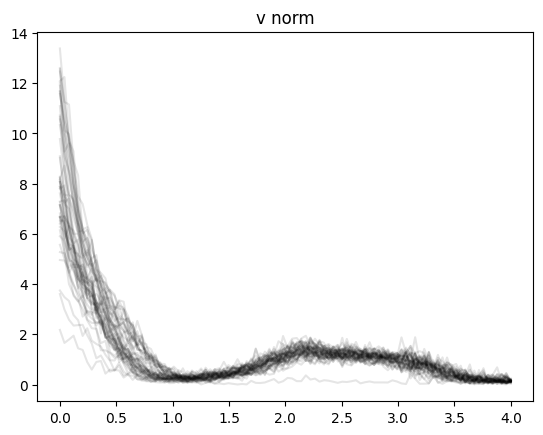

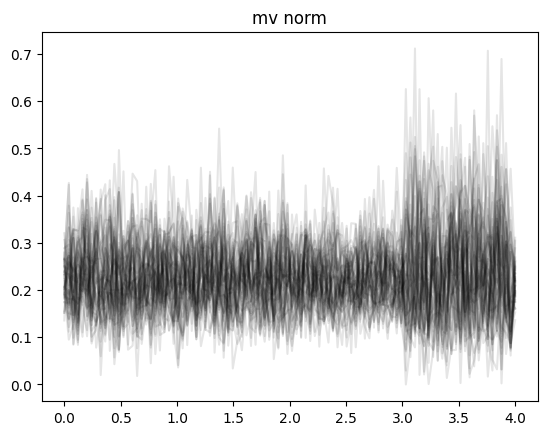

In [ ]:
plt.figure()
for i in range(n_points):
    plt.plot(sample_time.cpu().numpy(), v_norm[:,i], c='black', alpha=0.1)
    plt.title('v norm')
plt.figure()
for i in range(n_points):
    plt.plot(sample_time.cpu().numpy(), mv_norm[:,i], c='black', alpha=0.1)
    plt.title('mv norm')

In [ ]:
model.func.mean_velo_logit

Parameter containing:
tensor(-0.3285, requires_grad=True)

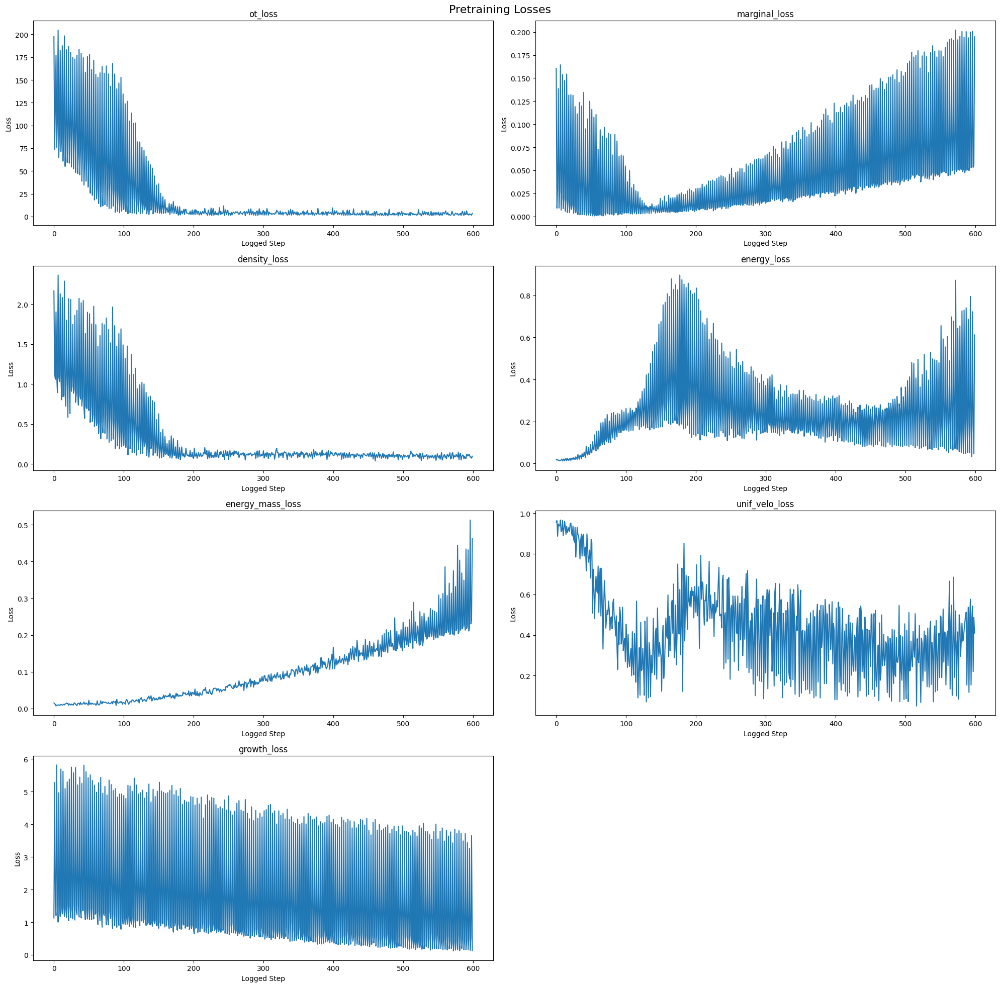

ValueError: Number of rows must be a positive integer, not 0

<Figure size 2000x0 with 0 Axes>

In [ ]:
# Create DataFrame
res_df = pd.DataFrame({k:v for k,v in losses_dict['pretraining'].items() if len(v) == len(losses_dict['pretraining']['ot_loss'])})

# Create a figure with subplots for each column
fig, axes = plt.subplots(nrows=(len(res_df.columns)+1)//2, ncols=2, figsize=(20, 5*((len(res_df.columns)+1)//2)))
fig.suptitle('Pretraining Losses', fontsize=16)

# Flatten axes array for easier iteration
axes = axes.flatten()

# Plot each column
for i, column in enumerate(res_df.columns):
    axes[i].plot(res_df.index, res_df[column])
    axes[i].set_title(column)
    axes[i].set_xlabel('Logged Step')
    axes[i].set_ylabel('Loss')

# Remove any unused subplots
for i in range(len(res_df.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Create DataFrame
res_df = pd.DataFrame({k:v for k,v in losses_dict['training'].items() if len(v) == len(losses_dict['training']['ot_loss'])})

# Create a figure with subplots for each column
fig, axes = plt.subplots(nrows=(len(res_df.columns)+1)//2, ncols=2, figsize=(20, 5*((len(res_df.columns)+1)//2)))
fig.suptitle('training Losses', fontsize=16)

# Flatten axes array for easier iteration
axes = axes.flatten()

# Plot each column
for i, column in enumerate(res_df.columns):
    axes[i].plot(res_df.index, res_df[column])
    axes[i].set_title(column)
    axes[i].set_xlabel('Logged Step')
    axes[i].set_ylabel('Loss')

# Remove any unused subplots
for i in range(len(res_df.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [ ]:
os.getcwd()

'/Users/xingzhi/Research/MIOFlow_growth_rate/notebooks/cflows_sep_model'

In [ ]:
# save model
save_path = './'
torch.save(model, f'{save_path}/model.pt')
torch.save(model.state_dict(), f'{save_path}/model_state_dict.pt')

In [ ]:
np.random.seed(32)
groups = sorted(df['samples'].unique())
sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
from MIOFlow.utils import sample
data_t0 = sample(
    df, np.min(groups), size=(n_points, ), 
    replace=False, to_torch=True, use_cuda=use_cuda
)
sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

with torch.no_grad():
    x_traj, m_traj = model(data_t0, sample_time, return_whole_sequence=True)

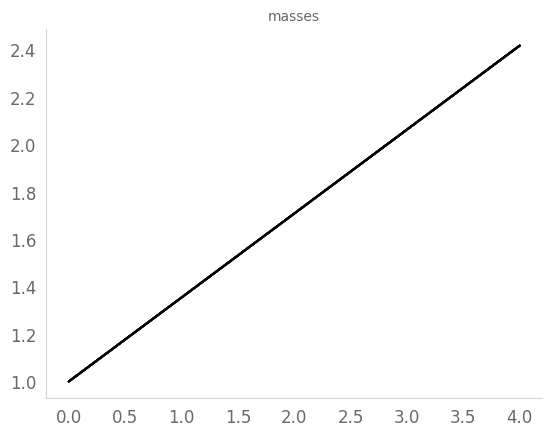

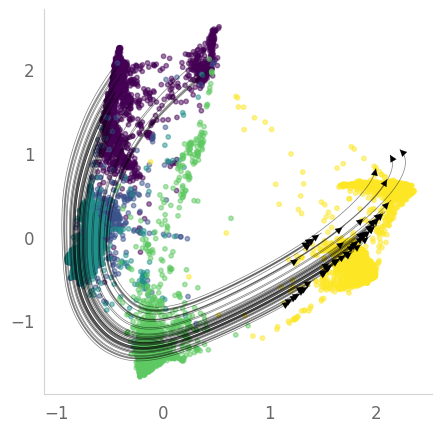

In [ ]:
plt.figure()
for i in range(n_points):
    plt.plot(sample_time.cpu().numpy(), m_traj.cpu().numpy()[:,i], c='black', alpha=0.1)
    plt.title('masses')

plt.figure(figsize=(5, 5))
plt.scatter(df['d1'], df['d2'],
                c=df['samples'] , cmap='viridis', s=10, alpha=.5)
for i,traj in enumerate(np.transpose(x_traj, axes=(1,0,2))):
    widths = m_traj[:,i]
    plt.plot(traj[:, 0], traj[:, 1], alpha=.5, linewidth=.5, color='Black');
    plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
                 arrowprops=dict(arrowstyle="-|>", color='Black', lw=.1))


In [ ]:
# save x_traj, m_traj
torch.save(x_traj, f'{save_path}/x_traj.pt')
torch.save(m_traj, f'{save_path}/m_traj.pt')

In [ ]:
np.random.seed(32)
groups = sorted(df['samples'].unique())
# sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
sample_time = groups
from MIOFlow.utils import sample
n_points_sample = 2000
data_t0 = sample(
    df, np.min(groups), size=(n_points_sample, ), 
    replace=False, to_torch=True, use_cuda=use_cuda
)
sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

from MIOFlow.losses import hard_softmax
# threshold_factor = 0.3
with torch.no_grad():
    xh, mh = model(data_t0, sample_time, return_whole_sequence=True)
    xmseq = torch.cat([xh, mh.unsqueeze(2)], dim=-1)
    dxdts = torch.stack([model.func(sample_time[i], xmseq[i]) for i in range(len(sample_time))])
m_rate = dxdts[..., -1].cpu().numpy()
xh, mh = xh.cpu().numpy(), mh.cpu().numpy()
m_rate_log = m_rate / mh
growth_rate = np.exp(m_rate_log)
xh_time_label = np.array(sample_time).repeat(n_points_sample, axis=0).reshape(-1)

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: Figure

<Axes: >

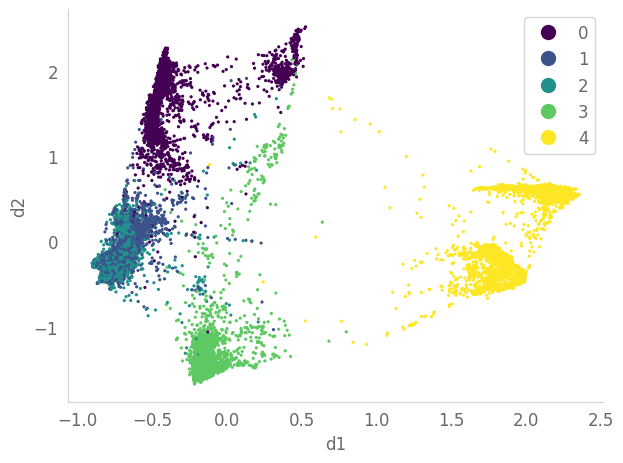

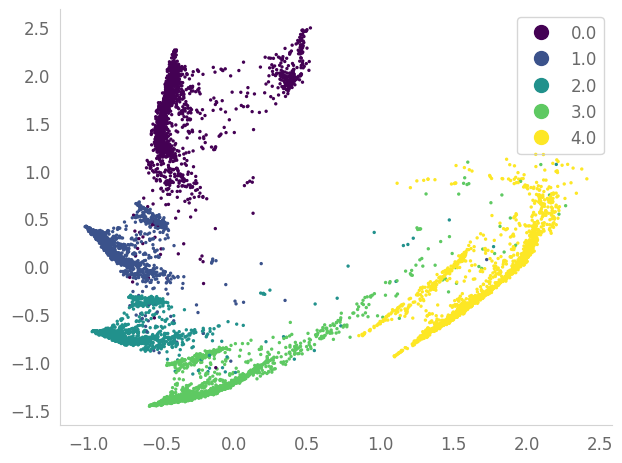

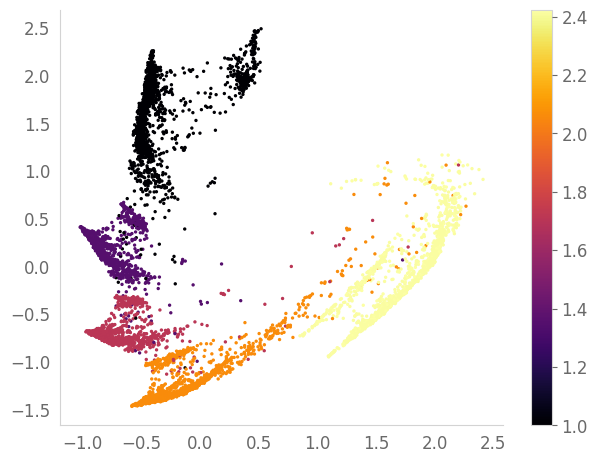

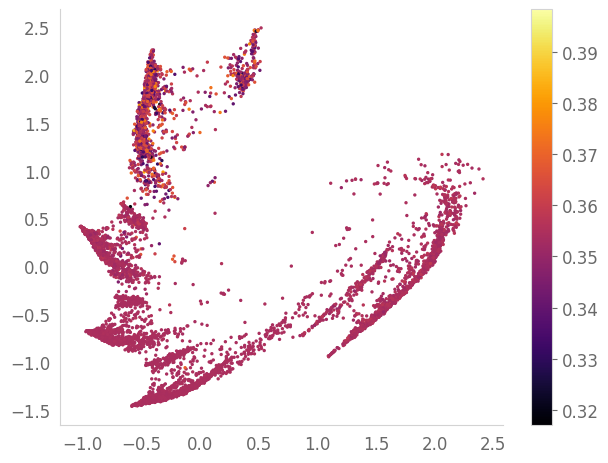

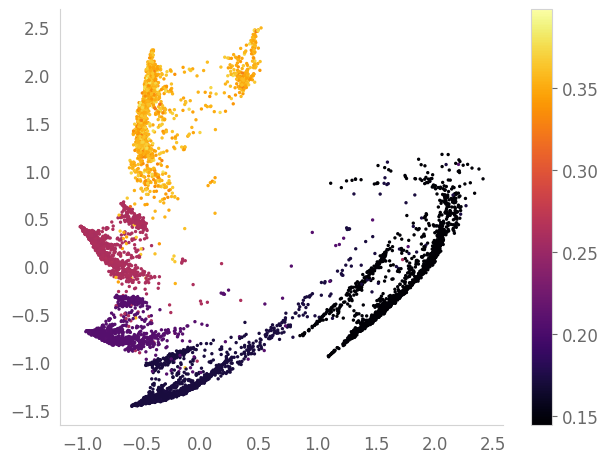

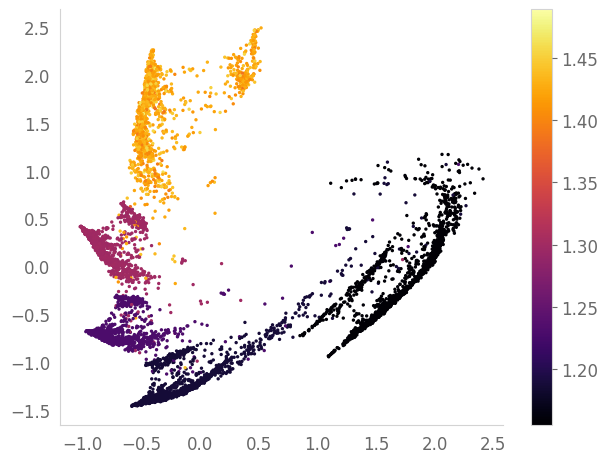

In [ ]:
import scprep
scprep.plot.scatter2d(df[['d1', 'd2']], c=df['samples'], cmap='viridis')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=xh_time_label, cmap='viridis')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=mh.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=m_rate.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=m_rate_log.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=growth_rate.reshape(-1), cmap='inferno')

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

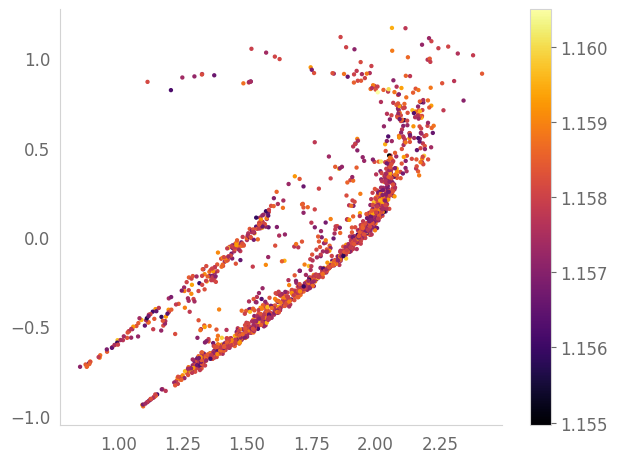

In [ ]:
scprep.plot.scatter2d(xh[-1,...], c=growth_rate[-1,...], cmap='inferno')

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

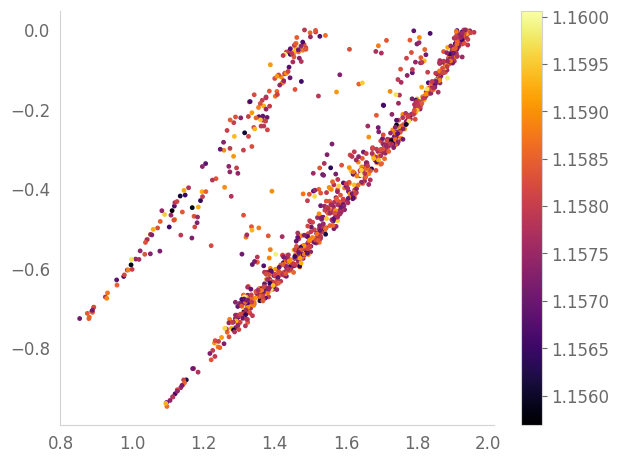

In [ ]:
xh0 = xh[-1,...]
growth_rate0 = growth_rate[-1,...]
xh0_mask = xh0[:,1]<0
xh00 = xh0[xh0_mask]
growth_rate00 = growth_rate0[xh0_mask]
scprep.plot.scatter2d(xh00, c=growth_rate00, cmap='inferno')

In [ ]:
torch.save(xh, f'{save_path}/xh.pt')
torch.save(mh, f'{save_path}/mh.pt')
torch.save(m_rate, f'{save_path}/m_rate.pt')
torch.save(m_rate_log, f'{save_path}/m_rate_log.pt')
torch.save(growth_rate, f'{save_path}/growth_rate.pt')

<Axes: xlabel='d1', ylabel='d2'>

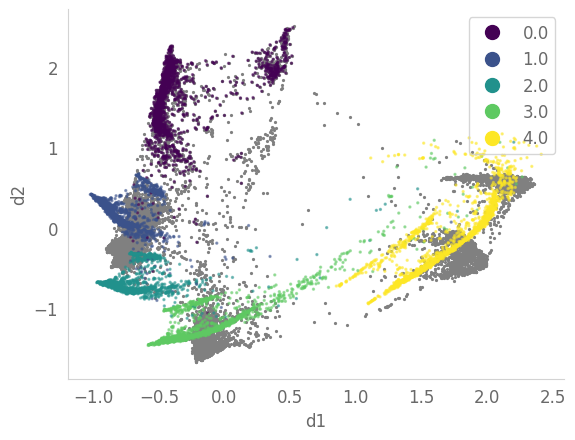

In [ ]:
import scprep
fig = plt.figure()
ax = fig.add_subplot(111); scprep.plot.scatter2d(df[['d1', 'd2']], c='gray', ax=ax)
scprep.plot.scatter2d(xh.reshape(-1, 2), c=xh_time_label, alpha=.5, cmap='viridis', ax=ax)

In [ ]:
import numpy as np
from scipy.spatial import cKDTree

df_phate = pd.read_csv('../../data/phate_data.csv')
df_phate['samples'] = df_phate['samples'].max() - df_phate['samples']

# Subsample the dataframe so each group has equal number of points
min_group_size = df_phate['samples'].value_counts().min()
df_phate_balanced = df_phate.groupby('samples').apply(lambda x: x.sample(min_group_size, random_state=42)).reset_index(drop=True)

# Verify the balanced dataset
print(df_phate_balanced['samples'].value_counts())

# Replace the original dataframe with the balanced one
df_phate = df_phate_balanced

# from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_phate[['d1', 'd2']] = scaler.fit_transform(df[['d1', 'd2']])
# drop the rows whose samples are 3
# df = df[df['samples'] != 3]

# Convert dataframes to numpy arrays
df_points = df_phate[['d1', 'd2']].values
xh_points = xh.reshape(-1, 2)

# Create a KD-tree for efficient nearest neighbor search
tree = cKDTree(xh_points)

# Find the index of the closest point in xh_points for each point in df_points
distances, indices = tree.query(df_points)

# Now 'indices' contains the index of the closest point in xh_points for each point in df_points
# You can use these indices to get the corresponding values from xh or other related arrays

# Example: Get the closest growth rates for each point in df
# closest_growth_rates = growth_rate.reshape(-1)[indices]
closest_growth_rates = m_rate.reshape(-1)[indices]
df_1 = df_phate.copy()
# Optionally, you can add the results back to the original dataframe
df_1['closest_xh_index'] = indices
df_1['closest_growth_rate'] = closest_growth_rates

# Print the first few rows to verify
print(df_1[['d1', 'd2', 'closest_xh_index', 'closest_growth_rate']].head())


samples
0    2832
1    2832
2    2832
3    2832
4    2832
Name: count, dtype: int64
         d1        d2  closest_xh_index  closest_growth_rate
0 -0.511085  1.221349              1221             0.348846
1 -0.512381  1.388856              1791             0.338957
2 -0.522036  1.362557               692             0.369904
3 -0.522126  1.313749              1891             0.357796
4 -0.493953  1.504457               506             0.359149


/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: xlabel='d1', ylabel='d2'>

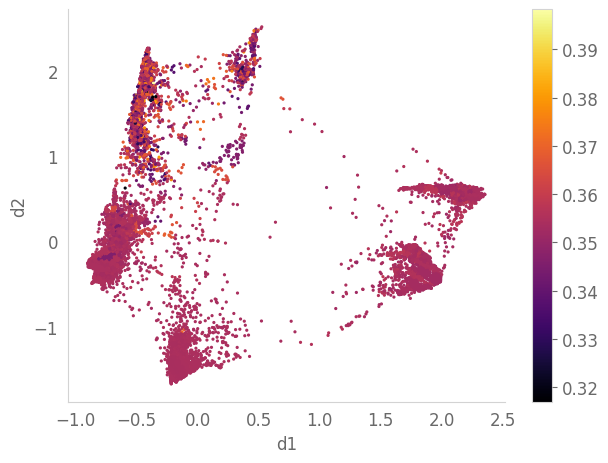

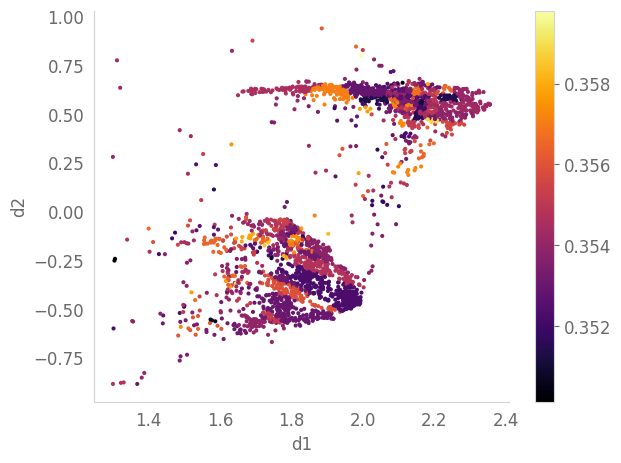

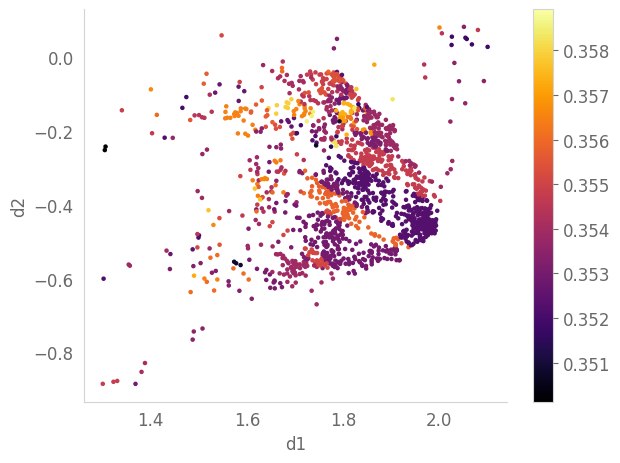

In [ ]:
scprep.plot.scatter2d(df_1[['d1', 'd2']], c=df_1['closest_growth_rate'], cmap='inferno')
scprep.plot.scatter2d(df_1[['d1', 'd2']][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<1.0)], c=df_1['closest_growth_rate'][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<1.0)], cmap='inferno')
scprep.plot.scatter2d(df_1[['d1', 'd2']][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<0.1)], c=df_1['closest_growth_rate'][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<0.1)], cmap='inferno')

In [ ]:
import pathlib
save_path = '../../results/trajpaper/'
pathlib.Path(save_path).mkdir(parents=True, exist_ok=True)
df_1.to_csv(f'{save_path}/df_w_growth_rate.csv', index=False)

torch.save(model, f'{save_path}/model.pt')
torch.save(model.state_dict(), f'{save_path}/model_state_dict.pt')

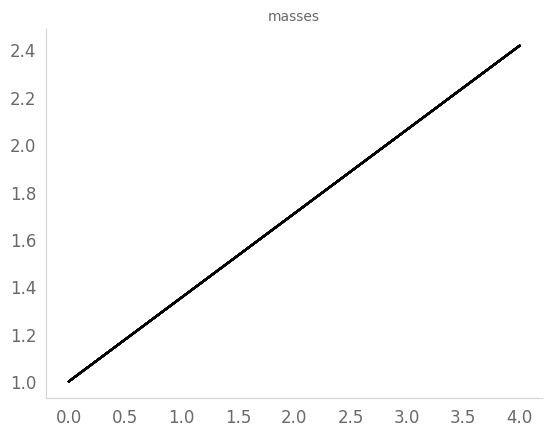

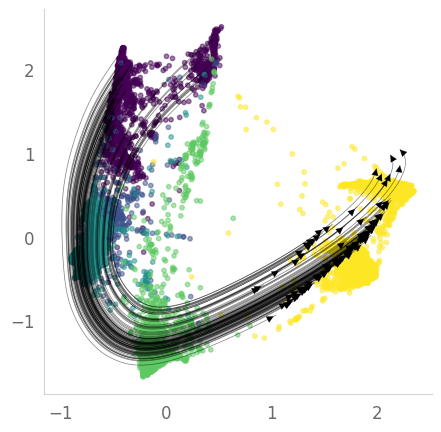

In [ ]:
n_points = 100
np.random.seed(32)
groups = sorted(df['samples'].unique())
sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
from MIOFlow.utils import sample
data_t0 = sample(
    df, np.min(groups), size=(n_points, ), 
    replace=False, to_torch=True, use_cuda=use_cuda
)
sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

with torch.no_grad():
    x_traj, m_traj = model(data_t0, sample_time, return_whole_sequence=True)

plt.figure()
for i in range(n_points):
    plt.plot(sample_time.cpu().numpy(), m_traj.cpu().numpy()[:,i], c='black', alpha=0.1)
    plt.title('masses')

plt.figure(figsize=(5, 5))
plt.scatter(df['d1'], df['d2'],
                c=df['samples'] , cmap='viridis', s=10, alpha=.5)
for i,traj in enumerate(np.transpose(x_traj, axes=(1,0,2))):
    widths = m_traj[:,i]
    plt.plot(traj[:, 0], traj[:, 1], alpha=.5, linewidth=.5, color='Black');
    plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
                 arrowprops=dict(arrowstyle="-|>", color='Black', lw=.1))

# save x_traj, m_traj
torch.save(x_traj, f'{save_path}/x_traj.pt')
torch.save(m_traj, f'{save_path}/m_traj.pt')

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/threadpoolctl.py:1010: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


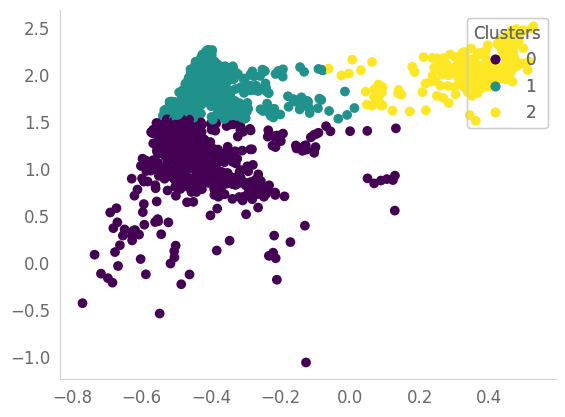

In [ ]:
# cluster "starting" points and annotate trajectories
np.random.seed(32)
t0_df = df[df['samples'] == 0].copy()
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3)
t0_df['cluster'] = kmeans.fit_predict(t0_df[['d1', 'd2']])
scatter = plt.scatter(t0_df['d1'], t0_df['d2'], c=t0_df['cluster'], cmap='viridis')

# Add legend
legend1 = plt.legend(*scatter.legend_elements(),
                    loc="upper right", title="Clusters")
plt.gca().add_artist(legend1)


In [ ]:
t0_df['cluster'].value_counts()

cluster
0    1298
1    1211
2     323
Name: count, dtype: int64

/var/folders/g2/pxzr9j95129bz38p7d4l_91r0000gn/T/ipykernel_94401/2743095603.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)
/var/folders/g2/pxzr9j95129bz38p7d4l_91r0000gn/T/ipykernel_94401/2743095603.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)


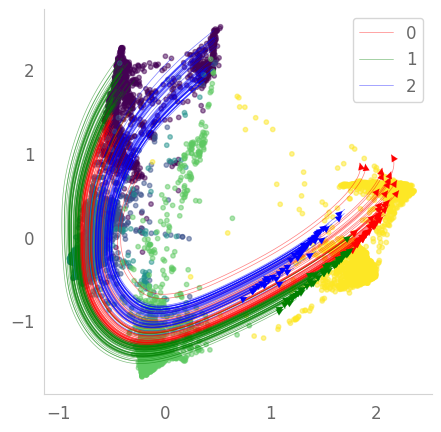

In [ ]:
n_points = 50
np.random.seed(32)
groups = sorted(df['samples'].unique())
sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
from MIOFlow.utils import sample
x_trajs, m_trajs = [], []
for i in t0_df['cluster'].unique():
    data_t0 = sample(
        t0_df[t0_df['cluster'] == i].drop(columns=['cluster']), np.min(groups), size=(n_points, ), 
        replace=False, to_torch=True, use_cuda=use_cuda
    )
    sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

    with torch.no_grad():
        x_traj, m_traj = model(data_t0, sample_time, return_whole_sequence=True)
    x_trajs.append(x_traj)
    m_trajs.append(m_traj)
# plt.figure()
# for i in range(n_points):
#     plt.plot(sample_time.cpu().numpy(), m_traj.cpu().numpy()[:,i], c='black', alpha=0.1)
#     plt.title('masses')

plt.figure(figsize=(5, 5))
plt.scatter(df['d1'], df['d2'],
                c=df['samples'] , cmap='viridis', s=10, alpha=.5)
colors = ['red', 'green', 'blue']  # Add more colors if needed
# legend_labels = []  # Add labels for each cluster
for j, (x_traj, m_traj) in enumerate(zip(x_trajs, m_trajs)):
    color = colors[j % len(colors)]  # Cycle through colors
    # label = legend_labels[j]  # Get the label for this cluster
    label = j
    for i, traj in enumerate(np.transpose(x_traj, axes=(1,0,2))):
        widths = m_traj[:,i]
        plt.plot(traj[:, 0], traj[:, 1], alpha=.5, linewidth=.5, color=color, label=label if i == 0 else "")
        plt.annotate('', xy=(traj[-1, 0], traj[-1, 1]), xytext=(traj[-2, 0], traj[-2, 1]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=.1))
plt.legend()  # Add the legend to the plot

traj_dict = {str(k):v.cpu().numpy() for k,v in zip(t0_df['cluster'].unique(), x_trajs)}
np.savez(f'{save_path}/traj_dict.npz', **traj_dict)


# save x_traj, m_traj
# torch.save(x_traj, f'{save_path}/x_traj.pt')

In [ ]:
phate_dims = 5
df = pd.read_csv('../../data/5-mioflow_data.csv')
df['samples'] = df['samples'].max() - df['samples']

# Subsample the dataframe so each group has equal number of points
min_group_size = df['samples'].value_counts().min()
df_balanced = df.groupby('samples').apply(lambda x: x.sample(min_group_size, random_state=42)).reset_index(drop=True)

# Verify the balanced dataset
print(df_balanced['samples'].value_counts())

# Replace the original dataframe with the balanced one
df = df_balanced

# from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[['d1', 'd2']] = scaler.fit_transform(df[['d1', 'd2']])
import pickle
with open(f'{save_path}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
# drop the rows whose samples are 3
# df = df[df['samples'] != 3]

samples
0    2832
1    2832
2    2832
3    2832
4    2832
Name: count, dtype: int64


In [ ]:
assert False

AssertionError: 

In [ ]:
import numpy as np
from scipy.spatial import cKDTree

# Convert dataframes to numpy arrays
df_points = df[['d1', 'd2']].values
xh_points = xh.reshape(-1, 2)

# Create a KD-tree for efficient nearest neighbor search
tree = cKDTree(xh_points)

# Find the index of the closest point in xh_points for each point in df_points
distances, indices = tree.query(df_points)

# Now 'indices' contains the index of the closest point in xh_points for each point in df_points
# You can use these indices to get the corresponding values from xh or other related arrays

# Example: Get the closest growth rates for each point in df
# closest_growth_rates = growth_rate.reshape(-1)[indices]
closest_growth_rates = growth_rate.reshape(-1)[indices]
df_1 = df.copy()
# Optionally, you can add the results back to the original dataframe
df_1['closest_xh_index'] = indices
df_1['closest_growth_rate'] = closest_growth_rates

# Print the first few rows to verify
print(df_1[['d1', 'd2', 'closest_xh_index', 'closest_growth_rate']].head())


         d1        d2  closest_xh_index  closest_growth_rate
0 -0.511085  1.221349              1221             1.712242
1 -0.512381  1.388856              1791             1.880294
2 -0.522036  1.362557               692             1.947704
3 -0.522126  1.313749              1891             1.930375
4 -0.493953  1.504457               506             1.973055


/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: xlabel='d1', ylabel='d2'>

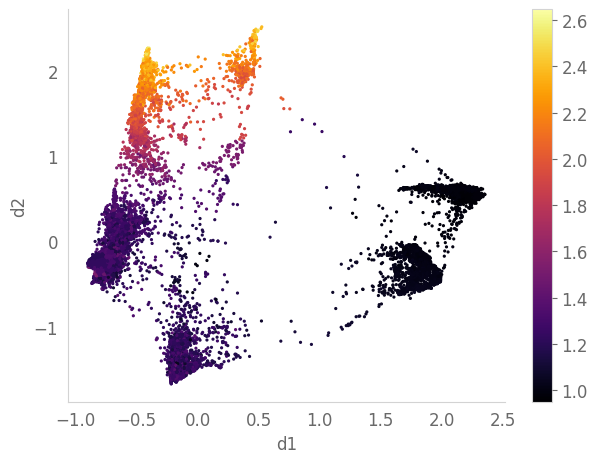

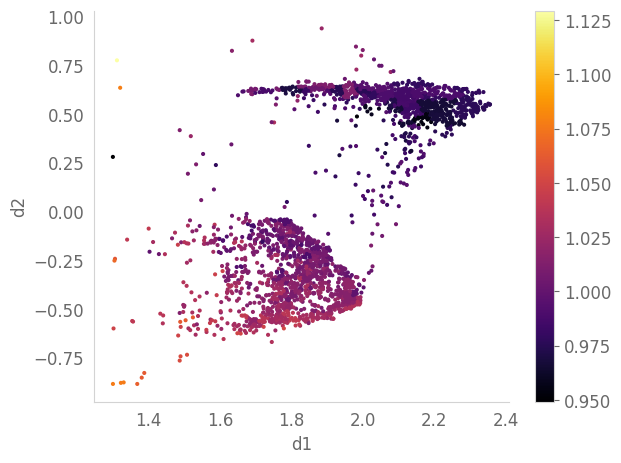

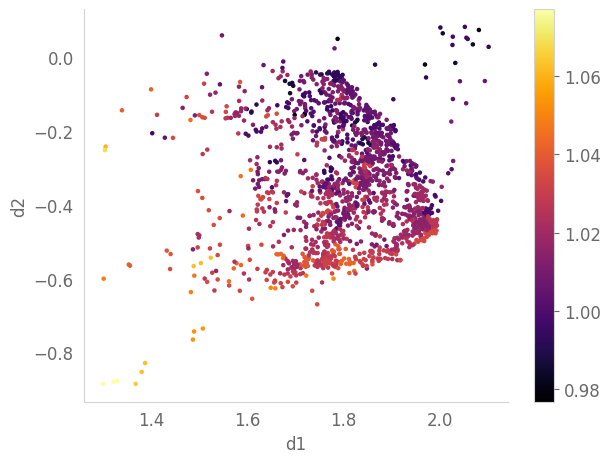

In [ ]:
scprep.plot.scatter2d(df_1[['d1', 'd2']], c=df_1['closest_growth_rate'], cmap='inferno')
scprep.plot.scatter2d(df_1[['d1', 'd2']][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<1.0)], c=df_1['closest_growth_rate'][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<1.0)], cmap='inferno')
scprep.plot.scatter2d(df_1[['d1', 'd2']][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<0.1)], c=df_1['closest_growth_rate'][(df_1['samples']==4) & (df_1['d1']>1.3) & (df_1['d2']<0.1)], cmap='inferno')

In [ ]:
assert False
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Convert dataframes to numpy arrays
np.random.seed(32)
df_sample = df.sample(n=1000)
df_points = df_sample[['d1', 'd2']].values
xh_points = xh.reshape(-1, 2)
growth_rate_values = growth_rate.reshape(-1)

# Perform kernel regression
kernel_reg = sm.nonparametric.KernelReg(growth_rate_values, xh_points, var_type=['c', 'c'], bw='cv')

# Predict smoothed growth rates for df_points
smoothed_growth_rates, _ = kernel_reg.fit(df_points)

# Create a new dataframe with the smoothed growth rates
df_1 = df_sample.copy()
df_1['smoothed_growth_rate'] = smoothed_growth_rates

# Print the first few rows to verify
print(df_1[['d1', 'd2', 'smoothed_growth_rate']].head())

# Plot results
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df_points[:, 0], df_points[:, 1], c=smoothed_growth_rates, cmap='viridis')
plt.colorbar(scatter, label='Smoothed Growth Rate')
plt.title('Kernel Regression: Smoothed Growth Rates')
plt.xlabel('d1')
plt.ylabel('d2')
plt.show()


KeyboardInterrupt: 

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: xlabel='d1', ylabel='d2'>

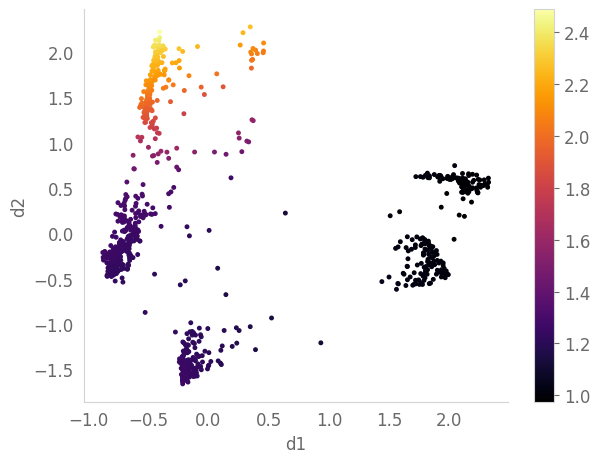

In [ ]:
scprep.plot.scatter2d(df_1[['d1', 'd2']], c=df_1['smoothed_growth_rate'], cmap='inferno')

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: xlabel='d1', ylabel='d2'>

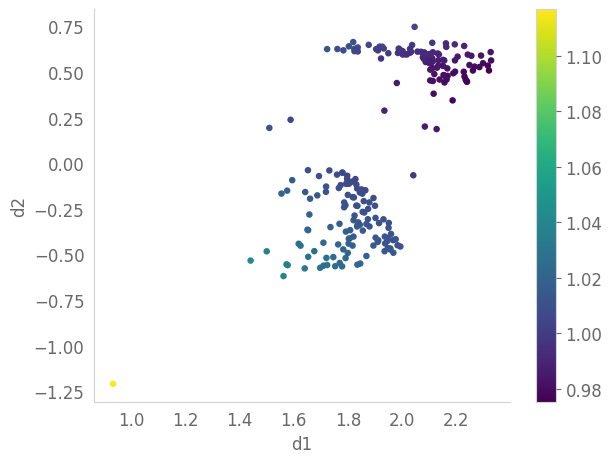

In [ ]:
scprep.plot.scatter2d(df_1[['d1', 'd2']][(df_1['samples']==4) & (df_1['d1']>0.6)], c=df_1['smoothed_growth_rate'][(df_1['samples']==4) & (df_1['d1']>0.6)], cmap='viridis')

In [ ]:
import scanpy as sc
all_data = df[['d1', 'd2']].values
adata = sc.AnnData(all_data)
adata.obsm['X_phate'] = all_data
adata.obs['samples'] = df['samples'].values
sc.pp.neighbors(adata, n_neighbors=15, use_rep='X_phate')
sc.tl.diffmap(adata)
adata.uns['iroot'] = np.argmin(adata.obsm['X_phate'][:,1])
sc.tl.dpt(adata)

In [ ]:
dpt_bin = pd.cut(adata.obs['dpt_pseudotime'].values, bins=3, labels=False)

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

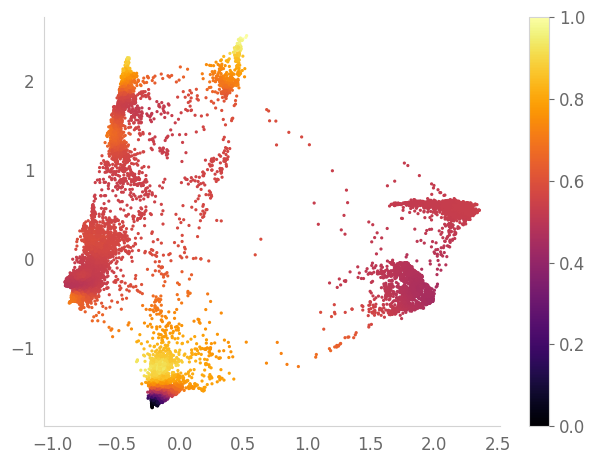

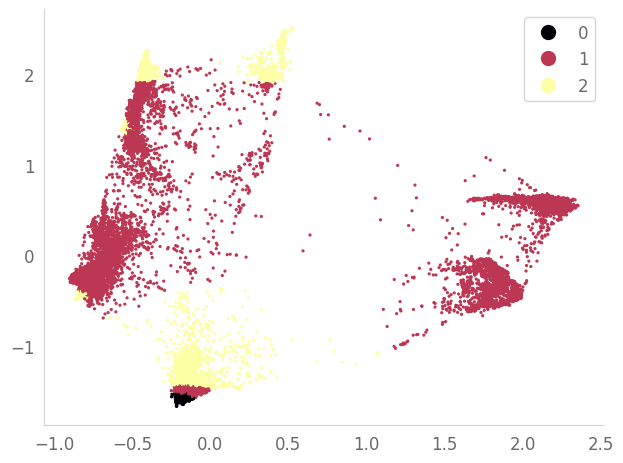

In [ ]:
scprep.plot.scatter2d(all_data, c=adata.obs['dpt_pseudotime'].values, cmap='inferno')
scprep.plot.scatter2d(all_data, c=dpt_bin, cmap='inferno')

In [ ]:
x = torch.tensor(last_tp, dtype=torch.float32)
t = torch.tensor(adata.obs['dpt_pseudotime'].values, dtype=torch.float32)

In [ ]:
model.

SyntaxError: invalid syntax (1068564517.py, line 1)

In [ ]:
assert False

In [ ]:
np.random.seed(32)
groups = sorted(df['samples'].unique())
n_bins = 10
sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
from MIOFlow.utils import sample
n_points_sample = 2000
data_t0 = sample(
    df, np.min(groups), size=(n_points_sample, ), 
    replace=False, to_torch=True, use_cuda=use_cuda
)
sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

# from MIOFlow.losses import hard_softmax
# threshold_factor = 0.3
with torch.no_grad():
    xh, mh = model(data_t0, sample_time, return_whole_sequence=True)
    xmseq = torch.cat([xh, mh.unsqueeze(2)], dim=-1)
    dxdts = torch.stack([model.func(sample_time[i], xmseq[i]) for i in range(len(sample_time))])
m_rate = dxdts[..., -1].cpu().numpy()
xh, mh = xh.cpu().numpy(), mh.cpu().numpy()
m_rate_log = m_rate / mh
xh_time_label = np.array(sample_time).repeat(n_points_sample, axis=0).reshape(-1)

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

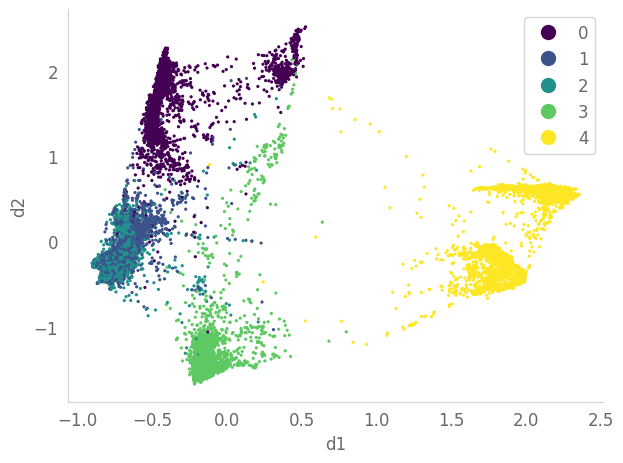

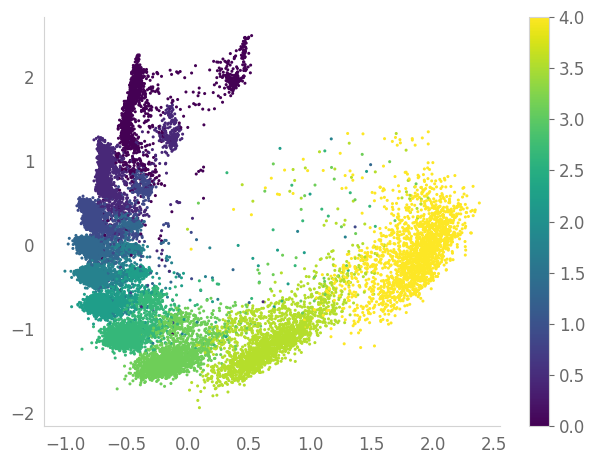

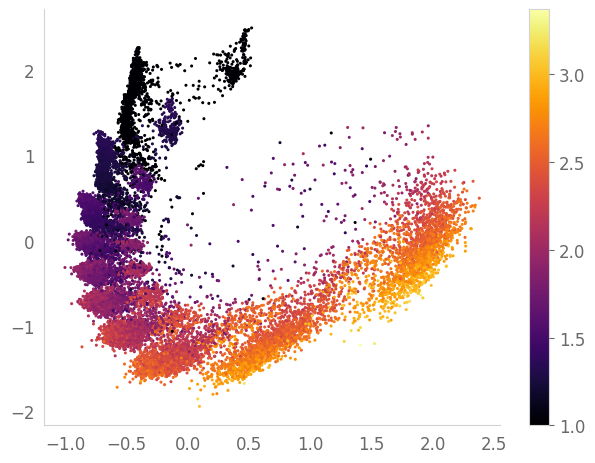

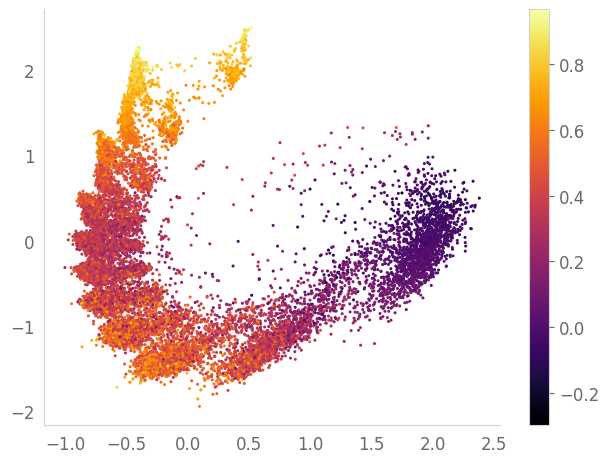

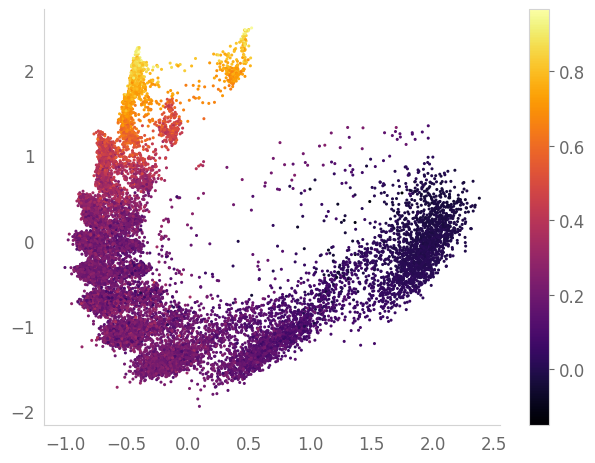

In [ ]:
import scprep
scprep.plot.scatter2d(df[['d1', 'd2']], c=df['samples'], cmap='viridis')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=xh_time_label, cmap='viridis')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=mh.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=m_rate.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=m_rate_log.reshape(-1), cmap='inferno')

<Axes: xlabel='d1', ylabel='d2'>

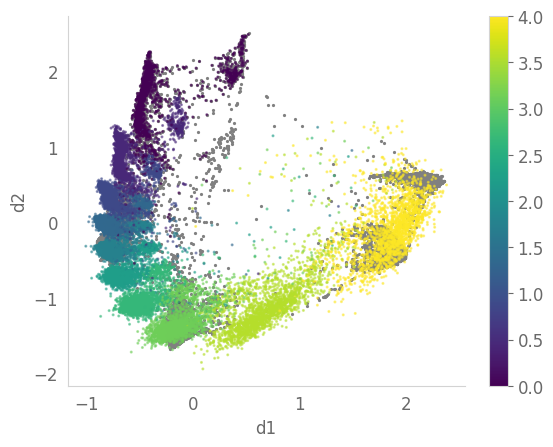

In [ ]:
import scprep
fig = plt.figure()
ax = fig.add_subplot(111); scprep.plot.scatter2d(df[['d1', 'd2']], c='gray', ax=ax)
scprep.plot.scatter2d(xh.reshape(-1, 2), c=xh_time_label, alpha=.5, cmap='viridis', ax=ax)

In [ ]:
np.random.seed(32)
groups = sorted(df['samples'].unique())
n_bins = 100
sample_time = np.linspace(np.min(groups), np.max(groups), n_bins)
from MIOFlow.utils import sample
n_points_sample = 50
data_t0 = sample(
    df, np.min(groups), size=(n_points_sample, ), 
    replace=False, to_torch=True, use_cuda=use_cuda
)
sample_time = torch.tensor(sample_time, dtype=data_t0.dtype, device=data_t0.device)

from MIOFlow.losses import hard_softmax
# threshold_factor = 0.3
with torch.no_grad():
    xh, mh = model(data_t0, sample_time, return_whole_sequence=True)
    xmseq = torch.cat([xh, mh.unsqueeze(2)], dim=-1)
    dxdts = torch.stack([model.func(sample_time[i], xmseq[i]) for i in range(len(sample_time))])
m_rate = dxdts[..., -1].cpu().numpy()
xh, mh = xh.cpu().numpy(), mh.cpu().numpy()
m_rate_log = m_rate / mh
xh_time_label = np.array(sample_time).repeat(n_points_sample, axis=0).reshape(-1)

/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/xingzhi/micromamba/envs/dmae/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

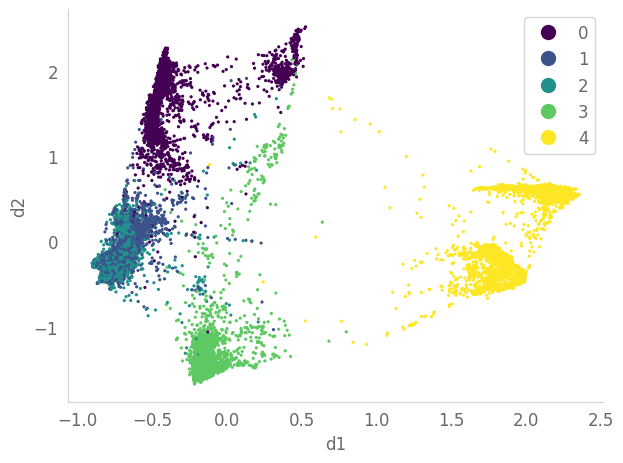

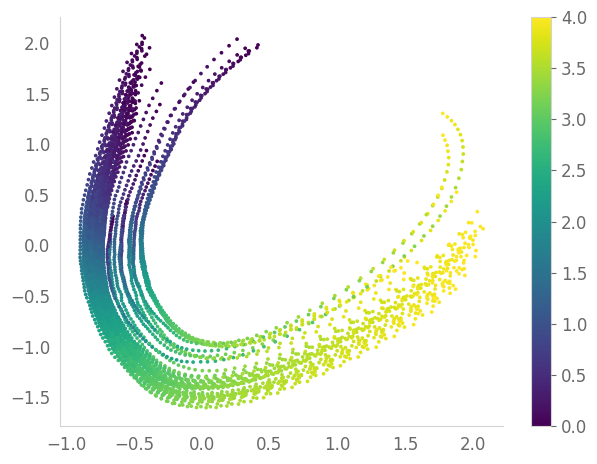

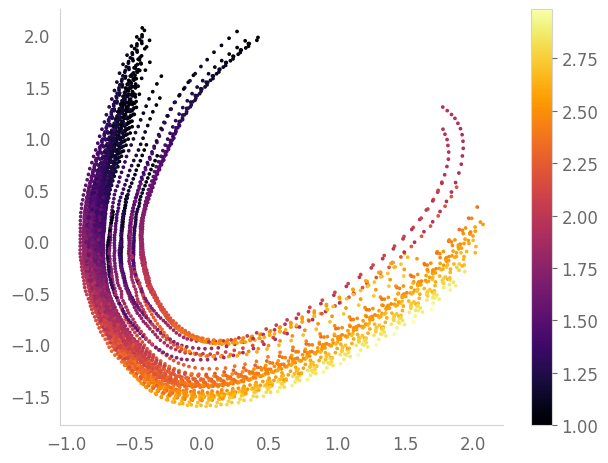

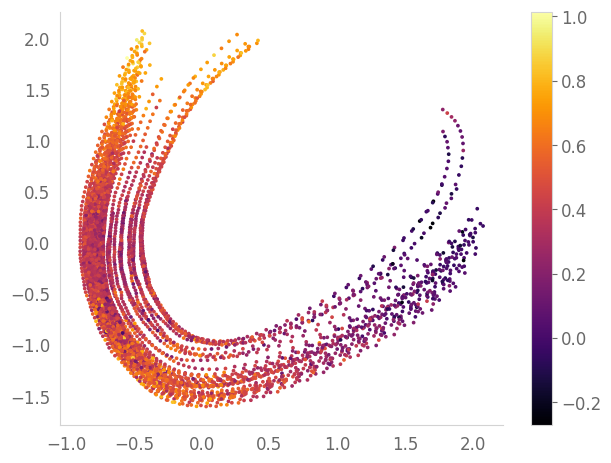

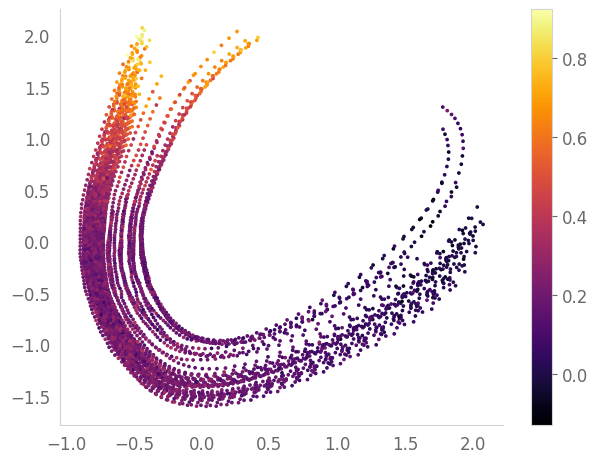

In [ ]:
import scprep
scprep.plot.scatter2d(df[['d1', 'd2']], c=df['samples'], cmap='viridis')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=xh_time_label, cmap='viridis')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=mh.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=m_rate.reshape(-1), cmap='inferno')
scprep.plot.scatter2d(xh.reshape(-1, 2), c=m_rate_log.reshape(-1), cmap='inferno')

<Axes: xlabel='d1', ylabel='d2'>

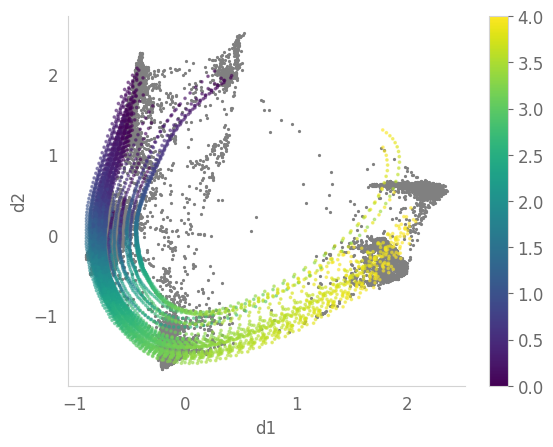

In [ ]:
import scprep
fig = plt.figure()
ax = fig.add_subplot(111); scprep.plot.scatter2d(df[['d1', 'd2']], c='gray', ax=ax)
scprep.plot.scatter2d(xh.reshape(-1, 2), c=xh_time_label, alpha=.5, cmap='viridis', ax=ax)